In [1]:
import pandas as pd
import random
from pydataquery import DataQuery
from matplotlib.colors import LinearSegmentedColormap
from xbbg import blp
import numpy as np
import pytz
import time
from datetime import datetime, timedelta
import statsmodels.api as sm
from ipywidgets import interact, Dropdown, HBox, VBox, Button, Output, Text, widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
import re
import scipy.stats as stats
from adjustText import adjust_text
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import sympy as sp
import itertools
import warnings
import openpyxl
import subprocess
import time
import pyautogui
import pygetwindow as gw
import pyodbc
import ast
warnings.filterwarnings("ignore")

In [2]:
try:
    df_original = pd.read_parquet("Markit CDS.parquet")
    
    to_date = datetime.today().date()
    from_date = df_original["close_date"].iloc[-1].date()
    
    from_date_str = from_date.strftime('%m/%d/%Y')
    to_date_str = to_date.strftime('%m/%d/%Y')
    
    conn_str = (
        f'DRIVER={{SQL Server}};'
        f'SERVER=BC-ODS-P1;'
        f'DATABASE=MarkitDB;'
        f'ApplicationIntent=ReadOnly;'
        f'Trusted_Connection=Yes;'
        f'Authentication=ActiveDirectoryIntegrated;'
    )
    
    conn = pyodbc.connect(conn_str)
    
    query1 = f"""
        DECLARE @FromDate DATE = '{from_date_str}';
        DECLARE @ToDate DATE = '{to_date_str}';
        
        SELECT sc.close_date, r.ticker, c.red, c.tier, c.docclause, c.ccy, sc.tenor, sc.spread
        FROM dbo.RedEntities r
        INNER JOIN dbo.MarkitCurves c ON r.red = c.red
        INNER JOIN dbo.MarkitSpreadCurve sc ON c.curve_id = sc.curve_id
        WHERE sc.close_date >= @FromDate AND sc.close_date <= @ToDate;
    """
    
    df_new = pd.read_sql(query1, conn)
    conn.close()

    df_old = df_original[df_original["close_date"]<pd.to_datetime(df_original["close_date"].iloc[-1])]

    df1 = pd.concat([df_old, df_new])
    df1 = df1.drop_duplicates()
    df1.to_parquet("Markit CDS.parquet")
except:
    df1 = pd.read_parquet("Markit CDS.parquet")
    hello = 1

In [3]:
markit_cds = list(set(df1["red"]))
markit_df1 = df1.copy()

res_codes = { "Full Restructuring": "CR14", "Modified Restructuring": "MR14",
          "Modified-Modified Restructurin": "MM14", "No Restructuring": "XR14"}

excel_df = None
all_dq = None
all_temp_cds = None

for rating_col in["IG","HY","EUR_IG","EUR_HY","SNRFIN","SUBFIN","Extras"]:
    dq = pd.read_excel("CDX Members.xlsx", sheet_name=rating_col)
    dq["Restructuring"] = dq["Restructuring"].apply(lambda x: res_codes[x])
    dq = dq[dq["Actual RED Code"].isin(markit_cds)].reset_index(drop=True).copy()
    dq.rename(columns={"Actual RED Code": "red"}, inplace=True)
    
    if not "Family" in dq.columns:
        dq["Family"] = [rating_col]*len(dq)
        
    if not "tier" in dq.columns:
        dq["tier"] = "SNRFOR" if rating_col != "SUBFIN" else "SUBLT2"
    
    dq["ccy"] = dq["Family"].apply(lambda x: "USD" if x in ["IG","HY"] else "EUR")
    dq = dq.drop(["5Y CDS Ticker","ISIN","RED Code","Company Name","Corp Ticker"],axis=1)
    
    all_dq = pd.concat([all_dq, dq]).drop_duplicates(keep="first").reset_index(drop=True).copy()

unique_all_dq = all_dq.drop("Family",axis=1).drop_duplicates().reset_index(drop=True).copy()
unique_all_dq.columns = unique_all_dq.columns.str.replace("Restructuring","docclause")

cds_df = pd.merge(left=df1, right = unique_all_dq, on=["red","docclause","tier","ccy"], how="inner")
cds_df["close_date"] = pd.to_datetime(cds_df["close_date"])
cds_df = cds_df[cds_df["tenor"]!="Spot"]
cds_df["tenor"] = cds_df["tenor"].apply(lambda x: eval(x.replace("y","*1").replace("m","*(1/12)")))

cds_df["ticker_red_tier_ccy_docclause"] = (cds_df["ticker"].astype(str) + "_" + cds_df["red"].astype(str) +\
     "_" + cds_df["tier"].astype(str) + "_" + cds_df["ccy"].astype(str) + "_" + cds_df["docclause"].astype(str))
cds_df = cds_df.drop(["ticker","red","tier","ccy","docclause"],axis=1)

########################### Creating map for family
f = all_dq.drop_duplicates().reset_index(drop=True).copy()
f1 = f["Issuer Equity"].astype(str) + "_" + f["red"].astype(str) + "_" +\
f["tier"].astype(str) + "_" + f["ccy"].astype(str)  + "_" + f["Restructuring"].astype(str)
f2 = f["Family"]
f_dict = dict(zip(f1,f2))

In [4]:
##############################################################################################################

issuers = list(sorted(set(cds_df["ticker_red_tier_ccy_docclause"])))
last_dt = max(cds_df["close_date"])

all_curves = None

try:
    # all_curves = pd.read_excel("All CDS Curves.xlsx/") ############## made to fail
    for issuer in issuers:
        df = cds_df[cds_df["ticker_red_tier_ccy_docclause"]==issuer]
        df = pd.pivot_table(df, values="spread", index="close_date", columns ="tenor")
        
        if not last_dt in df.index:
            df.loc[last_dt] = [np.nan] * len(df.columns)
        df = df.sort_index().ffill().copy()
        df[f"{issuer}_curve"] = [np.nan] * len(df)
    
        for idx in df.index:
            curve = df.loc[[idx],:].dropna(axis=1)
            curve = curve.iloc[:,:-1].copy()
            x = list((curve.columns))
            x2 = [item**2 for item in x]
            X = np.column_stack([x, x2])
            Y = list(curve.iloc[0])
    
            if len(X) > 2:
                model = sm.OLS(Y, sm.add_constant(X)).fit()
                df.loc[idx,f"{issuer}_curve"] = str([model.params[0], model.params[1], model.params[2]])
                
                # x_pred = list(np.linspace(min(x), max(x),100))
                # x_pred2 = [item**2 for item in x_pred]
                # X_pred = np.column_stack([x_pred, x_pred2])
                # y_pred = model.predict(sm.add_constant(X_pred))
                # plt.plot(x, Y)
                # plt.plot(x_pred, y_pred)
                # title = f"{issuer} on {str(idx.date())}"
                # plt.title(title)
                # # plt.savefig(f"Curve Plots v2/{title}.png")
                # plt.show()
                # plt.close()
                
            else:
                df.loc[idx,f"{issuer}_curve"] = str([np.nan, np.nan, np.nan])
    
        all_curves = pd.concat([all_curves,df.iloc[:,[-1]]],axis=1)
    all_curves.to_excel("All CDS Curves.xlsx")
except:
    all_curves = pd.read_excel("All CDS Curves.xlsx",index_col=0, parse_dates=True)
    hello=1

all_curves1 = all_curves.copy()
all_curves = all_curves.T.copy()
all_curves.index.name = "ticker_red_tier_ccy_docclause"
all_curves.columns = [f'CDS_{item.date()}' for item in all_curves.columns]
all_curves = all_curves.reset_index(drop=False).copy()
all_temp_cds = all_curves.copy()
all_temp_cds["Temp"] = (all_temp_cds["ticker_red_tier_ccy_docclause"].astype(str).\
    str.split("_", n=1).str[1].str.replace("_curve", "", regex=False))

In [5]:
unique_all_dq["Issuer Equity_red_tier_ccy_docclause"] = (unique_all_dq["Issuer Equity"].astype(str) + "_" + unique_all_dq["red"].astype(str) +\
     "_" + unique_all_dq["tier"].astype(str) + "_" + unique_all_dq["ccy"].astype(str) + "_" + unique_all_dq["docclause"].astype(str))
unique_all_dq = unique_all_dq.drop(["Issuer Equity","red","tier","ccy","docclause"],axis=1)
unique_all_dq["Temp"] = unique_all_dq["Issuer Equity_red_tier_ccy_docclause"].astype(str).str.split("_", n=1).str[1]

df2 = pd.merge(left=unique_all_dq, right=all_temp_cds, on="Temp", how="inner").drop(["Temp","ticker_red_tier_ccy_docclause"], axis=1)

In [6]:
markit_to_bbg_tier_map = {"SNRFOR": "Sr Unsecured", "SUBLT2": "Subordinated"}

l1 = [item.split("_")[0] for item in df2["Issuer Equity_red_tier_ccy_docclause"]]
l2 = [markit_to_bbg_tier_map[item.split("_")[2]] for item in df2["Issuer Equity_red_tier_ccy_docclause"]]
l3 = [item.split("_")[3] for item in df2["Issuer Equity_red_tier_ccy_docclause"]]
l4 = [item.split(" ")[0] for item in df2["Bond Name"]]
bbg_bonds_dict = {}

for i in range(len(l1)):
    bbg_bonds_dict[f"{l1[i]} Equity_{l2[i]}_{l3[i]}"] = l4[i]

In [7]:
# ##########################################################################This Data was copied to All Bonds sheet
# bql_list = []

# fl = [f"""=BQL("filter(bonds(['""",
#       f"""']), payment_rank=='""",
#       f"""' AND crncy=='""",
#       f"""')", "id_isin, id_cusip, name, maturity, amt_outstanding")"""]

# for item, key in bbg_bonds_dict.items():
#     bql_list += [fl[0] + item.split("_")[0] + fl[1] + item.split("_")[1] + fl[2] + item.split("_")[2] + fl[3]]

    
# bql_list = [item.replace("\\", "") for item in bql_list]

# workbook = openpyxl.load_workbook(r"J:\\HY Basis Data.xlsx")
# sheet = workbook.active

# for row in sheet.iter_rows():
#     for cell in row:
#         cell.value = None

# start_col = 1
# for item in bql_list:
#     cell = sheet.cell(row=2, column=start_col)
#     cell.value = item
#     start_col += 6
# workbook.save(r"J:\\HY Basis Data.xlsx")

# file_path = r"J:\\HY Basis Data.xlsx"
# window_title = "HY Basis Data - Excel"

# subprocess.Popen(['start', 'excel', file_path], shell=True)
# time.sleep(5)

# excel_windows = [window for window in gw.getWindowsWithTitle('Excel')]

# for window in excel_windows:
#     if window_title in window.title:
#         # time.sleep(0.5)
#         window.activate()
#         break

# time.sleep(45)
# pyautogui.hotkey('ctrl', 's')
# time.sleep(1)
# # pyautogui.hotkey('alt', 'f4')

# time.sleep(1.5)

In [8]:
bonds_map = []
markit_to_bbg_tier_map_reverse = dict(zip(list(markit_to_bbg_tier_map.values()), list(markit_to_bbg_tier_map.keys())))

for i in range(len(l1)):
    bonds_map += [f"{l1[i]}_{markit_to_bbg_tier_map_reverse[l2[i]]}_{l3[i]}"]

In [10]:
df = pd.read_excel("All Bonds.xlsx", sheet_name="All Bonds")
l5 = [item.split("_")[0].replace(" Equity","") + "_" + markit_to_bbg_tier_map_reverse[item.split("_")[1]] +\
      "_" + item.split("_")[2] for item in list(bbg_bonds_dict.keys())]
l6 = list(bbg_bonds_dict.values())

all_df = None

for i in range(len(df.columns))[::6]:
    x = df.iloc[:,i:i+6].dropna().copy()
    # display(l6[int(i/6)].split("_")[0])
    # display(df.iloc[:,i:i+6].dropna(how="all"))
    if len(x) > 0:
        x.columns = ['ID','ISIN', "CUSIP", 'Name', 'Maturity','Amt']
        x["Issuer Equity_tier_ccy"] = [l5[int(i/6)]] * len(x)
        x["Bond Name"] = [l6[int(i/6)]] * len(x)
        x["Check Col"] = x.apply(lambda row: row["Name"].split(" ")[0]==row["Bond Name"],axis=1)
        x = x[x["Check Col"]].drop(["Check Col","Bond Name"],axis=1)
        all_df = pd.concat([all_df, x])

all_df['Time'] = round(((pd.to_datetime(all_df['Maturity'])-datetime.now()).dt.days/365),2)
all_df = all_df[all_df["Time"]>=0]
all_df = all_df[(all_df['Time']>=4) & (all_df['Time']<=10)]
all_df = all_df[all_df['Amt']>=300*10**6]
all_df = all_df.reset_index(drop=True)
excel_df = pd.concat([excel_df, all_df])
all_df = excel_df.copy()

all_df = all_df.drop_duplicates(keep="first").reset_index(drop=True).copy()

########################################################################################### 144A and REGS

blist = [f'/isin/{item}@BGN' for item in list(all_df["ISIN"])]
blist = blp.bdp(tickers=blist, flds=["144A_FLAG","IS_REG_S"])
blist.to_parquet("144A.parquet")
blist = pd.read_parquet("144A.parquet")
blist.index = [item.rsplit("/",1)[1].split("@")[0] for item in blist.index]

blist.columns = ["144A","REGS"]
blist.index.name = "ISIN"
blist = blist.reset_index()
blist["REGS_144A"] = blist.apply(lambda row: f'{row["REGS"]}_{row["144A"]}',axis=1)
order = ["N_N", "Y_N", "Y_Y", "N_Y"]

all_df = pd.merge(left=all_df, right=blist, on="ISIN", how="outer")
all_df = all_df[[item for item in all_df.columns if not item in ["144A","REGS"]]]

all_df["REGS_144A"] = pd.Categorical(all_df["REGS_144A"], categories=order, ordered=True)
all_df = all_df.sort_values(by="REGS_144A")
all_df = all_df[~all_df["Name"].duplicated(keep='first')].drop(["REGS_144A","Time"],axis=1).reset_index(drop=True).copy()

In [11]:
t = [f"/isin/{item}@BGN" for item in list(all_df["ISIN"])]
bbg = blp.bdh(tickers=t, flds="BLOOMBERG_MID_G_SPREAD", start_date=datetime.now()-timedelta(days=365*5))
bbg.to_parquet("Test1.parquet")
bbg = pd.read_parquet("Test1.parquet")

bbg1 = bbg.copy()
new = []
for item in bbg1.columns:
    new += ["BBG_" + item[0].replace("/isin/","").replace("@BGN","")]
bbg1.columns = new
bbg1.index = pd.to_datetime(bbg1.index)

############################################################ choose bbg or dq sprds

bbg1.columns = [item.split("_")[1] for item in bbg1.columns]
bbg1.index = [f"Sprd_{str(item.date())}" for item in bbg1.index]
bbg1 = bbg1.T.copy()
bbg1.index.name = "ISIN"
bbg1 = bbg1.reset_index(drop=False).copy()

In [12]:
df2a = df2.drop(["Primary ISIN","Bond Name"],axis=1).copy()
df2a["Issuer Equity_tier_ccy"] = [item.split("_")[0] + "_" + item.split("_")[2] +\
               "_" + item.split("_")[3] for item in df2a["Issuer Equity_red_tier_ccy_docclause"]]

df3 = pd.merge(left=all_df, right=df2a, on="Issuer Equity_tier_ccy",\
               how="inner").drop(["ID","Amt","Issuer Equity_tier_ccy"],axis=1).copy()

for dt in pd.to_datetime(bbg.index):
    df3[f'Mat_Time_{dt.date()}'] = [((pd.to_datetime(item) - dt).days/365) for item in df3["Maturity"]]

df4A = df3.copy()
dt_list = [item.replace("CDS_","") for item in df4A.columns if item.startswith("CDS_")]

# for dt in dt_list:
#     if f"Mat_Time_{dt}" in df4A.columns and f"CDS_{dt}" in df4A.columns:
#         df4A[f'Mat_Matched_CDS_{dt}'] = df4A[f'CDS_{dt}'].apply(lambda x: ast.\
#             literal_eval(x)[0] if isinstance(x,str) else np.nan) +\
#         df4A[f'Mat_Time_{dt}'].apply(lambda x: x) *\
#         df4A[f'CDS_{dt}'].apply(lambda x: ast.literal_eval(x)[1] if isinstance(x,str) else np.nan) +\
#         df4A[f'Mat_Time_{dt}'].apply(lambda x: x**2) *\
#         df4A[f'CDS_{dt}'].apply(lambda x: ast.literal_eval(x)[2] if isinstance(x,str) else np.nan)

def safe_literal_eval(x):
    try:
        return ast.literal_eval(x) if isinstance(x, str) else [np.nan, np.nan, np.nan]
    except (ValueError, SyntaxError):
        return [np.nan, np.nan, np.nan]

for dt in dt_list:
    if f"Mat_Time_{dt}" in df4A.columns and f"CDS_{dt}" in df4A.columns:
        cds_values = df4A[f'CDS_{dt}'].apply(safe_literal_eval)
        mat_time = df4A[f'Mat_Time_{dt}']

        df4A[f'Mat_Matched_CDS_{dt}'] = (
            cds_values.apply(lambda x: x[0]) +
            mat_time * cds_values.apply(lambda x: x[1]) +
            mat_time**2 * cds_values.apply(lambda x: x[2]))

df4 = df4A[["ISIN","CUSIP","Name","Maturity","Issuer Equity_red_tier_ccy_docclause"] +\
    [col for col in df4A.columns if col.startswith("Mat_Matched_CDS")]].copy()

In [13]:
#################################################### Duration Data

dq_bonds = ['US50077LBF22','US49456BAG68','US49456BAR24','US49456BAV36','US49456BAX91','US500255AX28','US50077LAL09','US50077LAV80','US50077LBN55','US526057CY87','US530715AJ01','US501044DV05','US48666KAY55','US48666KAZ21','US48666KBA60','US620076BT59','US626717AP72','US63938CAN83','US63938CAP32','US63938CAQ15','US651229BD74','US549271AF19','US55262CAJ99','US552676AT59','US552676AU23','US552953CJ87','US552953CK50','US55342UAM62','US55616XAM92','US58013MFQ24','US382550BJ95','US382550BK68','US382550BR12','US382550BS94','US404119CA57','US404119CC14','US404119CK30','US404119CQ00','US404119CT49','US337932AL12','US337932AP26','US345370CA64','US345370CX67','US345370DA55','US345370DB39','US35671DBJ37','US35671DCD57','US35671DCF06','US35671DCH61','US36186CBY84','US36962GXZ26','US370334CL64','US370334CT90','US37045VAH33','US37045VAY65','US37045VAZ31','US404119DB22','US404121AK12','US458140BR09','US651229BE57','US44107TBC99','US40434LAN55','US42307TAG31','US432833AF84','US437076CB65','US44106MAY84','US44106MBB72','US44107TAY29','US44107TAZ93','US651229BF23','US89352HBA68','US893830AF64','US902494AZ66','US911363AM11','US911365BL76','US911365BP80','US91324PEJ75','US911365BN33','US88947EAU47','US85172FAR01','US87264ABF12','US87264ABT16','US87264ABW45','US87264ABX28','US87264ACB98','US87264ACQ67','US87264ACV52','US87264ADT97','US87901JAH86','US88033GAV23','US88167AAR23','US88167AAS06','US88167AAT88','US962166BR41','US963320AY28','US963320AZ92','US963320BA33','US963320BC98','US963320BD71','US963320BE54','US969457BB59','US969457BM15','US969457BZ28','US969457CJ76','US988498AN16','US988498AP63','US988498AR20','XS0161100515','US931142FC22','US92343VEU44','US92343VFX73','US92343VGN82','US92343VGY48','US92343VGZ13','US925524AH30','US925524AV24','US92556HAB33','US92556HAD98','US680665AK27','US682691AA80','US682691AE03','US682691AF77','US682691AG50','US682691AJ99','US682691AK62','US682691AL46','US68389XBV64','US68389XCE31','US68389XCH61','US68389XCJ28','US69047QAC69','US674599EL59','US674599EK76','US65339KCU25','US65339KDJ60','US65339KDK34','US65339KDL17',
'US674599DD43','US674599DE26','US674599EA94','US674599ED34','US674599EF81','US698900AG20','US75513ECR09','US78355HLC15','US78442FAZ18','US81761LAE20','US828807DT11','US716973AD41','US716973AE24','US717081EW90','US745867AM30','US745867AP60','US745867AT82','US74834LBC37','US30212PBH73','US1248EPCN14','US012873AK13','US012873AH83','US11135FAS02','US11135FBD24','US136385AE19','US134429BJ73','US126650DJ69','US00206RMM15','US126650DU15','US126650ED80','US031162DQ06','US026874DC84','US02406PBB58','US023551AM66','US023551AJ38','US097023CN34','US097023CP81','US097023CY98','US097023DC69','US097023DR39','US097023CJ22','US097023DS12','US023135AP19','US097023AU94','US023551AF16','US058498AW66','US058498AX40','US058498BA38','US07556QBT13','US08652BAB53','US071813BY49','US254709AS70','US244199BJ37','US247361ZT81','US251799AA02','US25179MBF95','US25179SAD27','US247361A329','US23331ABT51','US29273VAU44','US29273VBA70','US29278NAQ60','US30161NAX93','US30212PAR64','US29273VAT70','US29273RBE80','US28368EAD85','US28368EAE68','US292480AM22','US29273VAQ32','US292505AD65','US20030NEE76','US20030NDG34','US20030NBH35','US15089QAZ72','US15089QBA13','US15089QAY08','US00206RCP55','US15089QAP90','US00130HCG83','US15089QAX25','US205887AX04','XS2774392638','XS2655993033','XS3037720227','XS3023963534','XS3126635039','XS3106096178','XS3105513769','XS3091660194','XS2872799734','XS2870878456','XS2864439158','XS2811097075','XS2802883731','XS2826718087','XS2929387996','XS2922654418','XS2914769299','XS2904791774','XS2385393587','XS2116386132','XS2432162654','XS2247549731','XS2189766970','XS2300293003','XS2290544068','XS2056491587','XS2488809612','XS2010039894','FR001400WJR8','FR001400PAJ8','DE000A383HC1','CH0494734418','CH0591979627','DE000A4DFLQ6','US46284VAQ41','US501797AW48','US513272AD65','US513272AE49','US53219LAX73','US46284VAN10','US55617LAR33','US55617LAS16','US62482BAB80','US46284VAL53','US44332PAJ03','US46284VAF85','US37441QAA94','US428040DB25','US431318AV64','US431318AY04','US431318AZ78','US431318BC74','US431318BE31','US431318BG88','US432833AL52','US432833AN19','US432833AQ40','US432833AR23','US432833AS06','US44332PAG63','US62886HBP55','US46284VAJ08','US62886HBR12','US629377CS98','US629377CR16','US780153BV38','US780153BW11','US81211KAK60','US812127AB45','US812127AC28','US82967NBG25','US82967NBM92','US853496AG21','US853496AH04','US893830BZ10','US911365BR47','US92840VAP76','US92840VAR33','US947075AU14','US988498AL59','US780153BU54','US75606DAQ43','US737446AV69','US629377CW01','US629377CX83','US62957HAP01','US62957HAQ83','US63861CAF68','US64110LAU08','US64110LAV80','US677347CH71','US680665AN65','US68622FAB76','US68622TAB70','US737446AP91','US737446AQ74','US737446AR57','US737446AX26','US364760AQ18','US11135FBF71','US11135FBH38','US11135FBK66''US11135FBL40','US11135FBT75','US1248EPCD32','US1248EPCE15','US1248EPCK74','US1248EPCL57','US1248EPCP61','US1248EPCQ45''US1248EPCS01','US1248EPCT83','US126307BA42','US126307BB25','US103304BV23','US126307BD80','US097751CD18','US097751CB51','US00130HCC79','US01883LAD55','US01883LAH69','US03743QAQ10','US04433LAA08','US05368VAA44','US05368VAB27','US053773BH95','US053773BJ51','US053773BK25','US071734AJ60','US071734AL17','US097751AL51','US097751CA78','US097751CC35','US126307BF39','US126307BH94','US126307BK24','US224044CS42','US226373AT56','US23918KAS78','US23918KAT51','US23918KAW80','US23918KAY47','US185899AS01','US185899AR28','US12769GAA85','US12769GAD25','US131347CQ78','US143658BX94','US143658BY77','US364760AP35','US143658BZ43','US17888HAB96','US17888HAC79','US17888HAD52','US185899AL57','US185899AN14','US185899AP61','US185899AQ45','US143658CA82']

dq_bonds = list(df4["ISIN"])
all_labels = dict(zip(df4["ISIN"],[f"DB(CREDIT,HY,BOND,{item},MDUR)" for item in df4["CUSIP"]]))

labels = {}
for item in dq_bonds:
    labels[f"{item}_Dur"] = all_labels[item]

try:
    df1 = pd.read_excel("DQ HY Duration Data.xlsx/",index_col=0, parse_dates=True)
    dq = DataQuery(
        client_id='jbAIMF2Tkp0JO3sc',
        client_secret='d7qfzgt55pddjs352sgxosFyI4t2eja07k7opbi6wg9oqjc1OjkdAksn1btmnugeMjchcx2vwTsJupw',
        calendar = 'CAL_USBANK',
    )
    
    job = dq.create_job(expressions = list(labels.values()))
    dq.start_date = str((datetime.now()-timedelta(days=5*365)).date())
    job.execute(alert_long_requests='ignore')
    df = job.to_pivot_table()
    df = df.T
    df.index.name = 'Date'
    df.index = pd.to_datetime(df.index, format='%Y%m%d').date
    df.columns.name = None
    
    df1 = pd.DataFrame()
    for key in labels:
        df1[key] = df[labels[key]]
    
    df1 = df1[list(labels.keys())].copy()
    clear_output(wait=False)
    df1.dropna(axis=1, how='all', inplace=True)
    df1.to_excel("DQ HY Duration Data.xlsx")
except:
    df1 = pd.read_excel("DQ HY Duration Data.xlsx",index_col=0, parse_dates=True)

In [14]:
df1a = df1.copy()
df1a = df1a.T
df1a.index = df1a.index.str.replace("_Dur","")
df1a.columns = ["Dur_" + str(item.date()) for item in df1a.columns]
df1a.index.name="ISIN"
df1a = df1a.reset_index()

df4B = pd.merge(left=df4, right=df1a, on="ISIN", how="outer")

####################################################################

t = [f"/isin/{item}@BGN" for item in list(all_df["ISIN"])]
px = blp.bdh(tickers=t, flds="PX_LAST", start_date=datetime.now()-timedelta(days=365*5))
px.to_parquet("Test2.parquet")
px = pd.read_parquet("Test2.parquet")

new = []
for item in px.columns:
    new += [item[0].replace("/isin/","").replace("@BGN","")]
px.columns = new
px = px.T
px.columns = ["Price_" + str(item) for item in px.columns]
px.index.name= "ISIN"
px = px.reset_index()

####################################################
df5a = pd.merge(left=df4B, right=bbg1, on="ISIN", how="inner")
last_update = max(dt_list)
for dt in dt_list:
    try:
        df5a[f"Basis_{dt}"] = df5a[f"Mat_Matched_CDS_{dt}"] - df5a[f"Sprd_{dt}"]
    except:
        hello = 1

df5a = pd.merge(left=df5a, right=px, on="ISIN", how="inner")

In [15]:
df5 = df5a.copy()
df5 = df5[["ISIN","CUSIP","Name","Maturity","Issuer Equity_red_tier_ccy_docclause"] +\
    [col for col in df5.columns if last_update in col or "Basis_" in col]].copy()

####################################### Zscore and 1Y High/Low Calc

dfz = df5[["ISIN"] + [item for item in df5.columns if "Basis" in item]]
dfz = dfz.set_index("ISIN").T
dfz.index = [pd.to_datetime(item.split("_")[1]).date() for item in dfz.index]
dfz = dfz.sort_index()

all_z_df = None
for period in [3*22, 6*22, 12*22]:
    x = ((dfz-dfz.rolling(period, min_periods = int(0.6*period)).mean())/dfz.rolling(period,\
                  min_periods = int(0.6*period)).std()).iloc[[-1],:].copy()
    x.index = [f'ZScore_{int(period/22)}M']
    all_z_df = pd.concat([all_z_df , x])

max_1y = pd.DataFrame(dfz.iloc[-12*22:,:].max()).T
max_1y.index = [f'Basis 1Y High']
min_1y = pd.DataFrame(dfz.iloc[-12*22:,:].min()).T
min_1y.index = [f'Basis 1Y Low']

all_z_df = pd.concat([all_z_df , max_1y, min_1y])
all_z_df = all_z_df.T
all_z_df = all_z_df.reset_index()

df6 = pd.merge(left=df5.drop([col for col in df5.columns if col.\
    startswith("Basis_") and not last_update in col],axis=1),\
               right=all_z_df, on="ISIN", how="inner").drop(["CUSIP","Maturity"],axis=1).copy()

In [16]:
try:
    df7 = df6.drop(f"Dur_{last_update}",axis=1).copy()
    df7["Family"] = df7["Issuer Equity_red_tier_ccy_docclause"].apply(lambda x: f_dict[x])
    df7["CDS RED Code"] =  df7["Issuer Equity_red_tier_ccy_docclause"].apply(lambda x: x.split("_")[1])
    df7.columns = df7.columns.str.replace(f"_{last_update}","").str.replace("Mat_Matched_CDS","Mat. Matched CDS")
    df7["First Sort"] = df7["Name"].apply(lambda x: x.split(" ")[0])
    df7["Second Sort"] = df7["Name"].apply(lambda x: x.rsplit("/")[-1])
    
    df7 = df7.sort_values(by=["First Sort","Second Sort"],ascending=[True, True])
    df7 = df7.drop(["ISIN","Issuer Equity_red_tier_ccy_docclause","First Sort","Second Sort"], axis=1).set_index("Name").copy()
    
    df7 = df7[["Family","CDS RED Code","Price","Sprd","Mat. Matched CDS","Basis","Basis 1Y Low","Basis 1Y High",\
               "ZScore_3M","ZScore_6M","ZScore_12M"]].copy()
    df7 = round(df7,2)
except:
    pass

KeyError: "['Dur_2025-09-03'] not found in axis"

In [17]:
A = df5a[["ISIN"]+[col for col in df5a.columns if col.startswith("Mat_Matched_CDS_")]].set_index("ISIN")
A = A.T
A.index = pd.to_datetime(A.index.str.replace("Mat_Matched_CDS_",""))
A.columns = [f"{item}_Mat_Matched_CDS_" for item in A.columns]

B = df5a[["ISIN"]+[col for col in df5a.columns if col.startswith("Basis_")]].set_index("ISIN")
B = B.T
B.index = pd.to_datetime(B.index.str.replace("Basis_",""))
B.columns = [f"{item}_Basis" for item in B.columns]

C = df5a[["ISIN"]+[col for col in df5a.columns if col.startswith("Sprd_")]].set_index("ISIN")
C = C.T
C.index = pd.to_datetime(C.index.str.replace("Sprd_",""))
C.columns = [f"{item}_G-Sprd" for item in C.columns]

D = df5a[["ISIN"]+[col for col in df5a.columns if col.startswith("Price_")]].set_index("ISIN")
D = D.T
D.index = pd.to_datetime(D.index.str.replace("Price_",""))
D.columns = [f"{item}_Price" for item in D.columns]

E = df5a[["ISIN"]+[col for col in df5a.columns if col.startswith("Dur_")]].set_index("ISIN")
E = E.T
E.index = pd.to_datetime(E.index.str.replace("Dur_",""))
E.columns = [f"{item}_Dur" for item in E.columns]
E = E.dropna(how='all',axis=1)

for item in ["A","B","C","D","E"]:
    globals()[f"{item}"].index = pd.to_datetime(globals()[f"{item}"].index)

F = pd.concat([A,B,C,D,E], axis=1).sort_index().copy()

In [18]:
# ######################### HY bonds TR data from BBG using BQL

# import openpyxl
# import subprocess
# import time
# import pyautogui
# import pygetwindow as gw
    
# if True:
#     bql_list = []
    
#     fl = [f'=BQL("', f"""ISIN", "return_series(calc_interval=range(-5y,0d,frq=d))")"""]
    
#     issuers = df6["ISIN"].to_list()
    
#     for item in issuers:
#         bql_list += [(fl[0] + item + " " + fl[1])]
        
#     bql_list = [item.replace("\\", "") for item in bql_list]
    
#     workbook = openpyxl.load_workbook(r"J:\\55 BQL HY Bonds Rtn Data.xlsx")
#     sheet = workbook.active
    
#     for row in sheet.iter_rows():
#         for cell in row:
#             cell.value = None
    
#     start_col = 1
#     for item in bql_list:
#         cell = sheet.cell(row=2, column=start_col)
#         cell.value = item
#         start_col += 2
#     workbook.save(r"J:\\55 BQL HY Bonds Rtn Data.xlsx")
    
#     file_path = r"J:\\55 BQL HY Bonds Rtn Data.xlsx"
#     window_title = "55 BQL HY Bonds Rtn Data - Excel"
    
#     subprocess.Popen(['start', 'excel', file_path], shell=True)
#     time.sleep(40)
    
#     excel_windows = [window for window in gw.getWindowsWithTitle('Excel')]
    
#     for check in range(2):
#         for window in excel_windows:
#             if window_title in window.title:
#                 # time.sleep(0.25)
#                 window.activate()
#                 pyautogui.hotkey('ctrl', 's')
#                 time.sleep(1)
#                 pyautogui.hotkey('alt', 'f4')
#                 # break
    
# time.sleep(0.5)

# hy = pd.read_excel(r"J:\\55 BQL HY Bonds Rtn Data.xlsx",skiprows=1,parse_dates=True)
# hy = hy.iloc[1:,:]
# hy = hy[[hy.columns[0]] + [col for col in hy.columns if "ISIN" in col]]
# hy.columns = ["Date"] + [item.replace(" ISIN","_Daily_Rtn") for item in list(hy.columns)[1:]]
# hy = hy.set_index("Date")
# hy.index = pd.to_datetime(hy.index)
# hy = (1+hy).cumprod()
# hy_col = hy.columns
# for col in hy_col:
#     hy[f'{col.split("_")[0]} FWD_1M_Rtn'] = (hy[col].shift(-21) / hy[col] - 1) * 100
#     hy[f'{col.split("_")[0]} FWD_3M_Rtn'] = (hy[col].shift(-63) / hy[col] - 1) * 100
#     hy[f'{col.split("_")[0]} FWD_6M_Rtn'] = (hy[col].shift(-126) / hy[col] - 1) * 100
# hy = hy[[col for col in hy.columns if "FWD" in col]]

In [19]:
# df = pd.concat([F, hy],axis=1).sort_index().copy()

df = F.sort_index().copy()
df.columns = df.columns.str.replace("_Mat_Matched_CDS_"," Mat. Matched CDS").\
    str.replace("_Basis"," Basis").str.replace("_Dur"," Duration").\
    str.replace("_Price"," Price").str.replace("_G-Sprd"," G-Sprd")

bond_dict = dict(zip(list(df5a["ISIN"]),list(df5a["Name"])))
df.columns = [f"{bond_dict[item.split(" ",1)[0]]} {item.split(" ",1)[1]}"  for item in df.columns]
df = df.dropna(how="all").copy()
df.columns = [f"{item.split("/",1)[0].rsplit(" ",1)[0]}% due {item.\
    rsplit("/",1)[1]}" for item in df.columns]

In [20]:
tickers_bbg = ['IBOXHY INDEX', 'IBOXIG INDEX']
fields_bbg = ['PX_LAST', 'CONTRBTD_ZSPREAD', 'OAS_SOVEREIGN_CURVE', 'OPTION_ADJ_DURATION_SOV_CRV', 'YIELD_TO_MATURITY']
start_date_bbg = "2000-01-01"
end_date_bbg = datetime.now().strftime('%Y-%m-%d')
df_bbg = blp.bdh(tickers=tickers_bbg, flds=fields_bbg, start_date=start_date_bbg, end_date=end_date_bbg)
list1_bbg = ['TR', 'Z-Sprd', 'OAS', 'Dur', 'Yield']
df_bbg.columns = ['BBG iBoxx HY ' + item for item in list1_bbg] + ['BBG iBoxx IG ' + item for item in list1_bbg] 
df_bbg.drop(['BBG iBoxx HY Dur', 'BBG iBoxx IG Yield'], axis=1, inplace=True) # First is wrong and second incomplete
df_bbg = df_bbg.astype(float)

tick = ['USGG5YR INDEX','USGG7YR INDEX','USGG10YR INDEX']
all_x = None
x = blp.bdh(tickers = tick, flds = 'PX_LAST', start_date = df_bbg.index[0])#, end_date = df_bbg.index[-1])
for col in ['BBG']:# + list(set([item.split(' ',1)[0] for item in df_back.columns])):
    x1 = x.copy()
    x1.columns = [f'{col} US 5Y', f'{col} US 7Y', f'{col} US 10Y']
    all_x = pd.concat([all_x,x1],axis=1)
df_bbg = pd.concat([df_bbg,all_x],axis=1)

tick = ['COA Comdty','VIX Index']
x = blp.bdh(tickers = tick, flds='PX_LAST', start_date = df_bbg.index[0])#, end_date = df_bbg.index[-1])
x.columns = ['BBG COA Comdty','BBG VIX Index']
x = x.sort_index()
df_bbg = pd.concat([df_bbg,x],axis=1)
df_bbg.index = pd.to_datetime(df_bbg.index)

backup = df.copy()
df = pd.concat([backup, df_bbg], axis=1).sort_index().copy()

In [21]:
options = sorted(backup.columns, key=lambda item: (item.split(' ', 1)[0], 2000 + \
            eval(item.split('due ', 1)[1].split(' ', 1)[0]) if eval(item.split('due ', 1)[1].split(' ', 1)[0])\
                    < 2000 else eval(item.split('due ', 1)[1].split(' ', 1)[0])))

options += list(df_bbg.columns)
fwd = [item for item in options if 'FWD_' in item]
non_fwd = [item for item in options if not('FWD_' in item)]
options = non_fwd + fwd

time = ['All','2Y','1Y','6M','3M']

#################################### Changing order of names
o1 = [item for item in options if ((not 'FWD' in item) and ('%' in item))]
o2 = [item for item in options if not item in o1]

desired_order = ["Price", "G-Sprd", "Basis", "Duration", "CDS"]

def reorder_items_in_chunks(items, order):
    chunk_size = len(set([item.rsplit(' ',1)[1] for item in options if ((not 'FWD' in item) and ('%' in item))]))
    reordered = []
    for i in range(0, len(items), chunk_size):
        chunk = items[i:i + chunk_size]
        valid_items = [item for item in chunk if len(item.rsplit(' ', 1)) == 2]
        reordered_chunk = sorted(valid_items, key=lambda x: order.index(x.rsplit(' ', 1)[1]))
        reordered.extend(reordered_chunk)
    return reordered

o1_reordered = reorder_items_in_chunks(o1, desired_order)
options = o1 + o2

In [22]:
############ Default bonds
# x = df5a[["Name","ISIN"]].copy()
# x["Eqty Name"] = df5a["Issuer Equity_red_tier_ccy_docclause"].apply(lambda x: x.split("_")[0])
# issue = blp.bdp(tickers=[f"/isin/{item}@BGN" for item in x["ISIN"]], flds="ISSUE_DT")
# issue1 = issue.copy()
# issue1.index = issue1.index.str.replace("/isin/","").str.replace("@BGN","")
# issue1.index.name = "ISIN"
# issue1 = issue1.reset_index()
# x = pd.merge(left=x, right=issue1, on="ISIN", how="outer")
# x["Age"] = round((datetime.now() - pd.to_datetime(x["issue_dt"])).dt.days/365,2)
# x = x[["Name","Eqty Name","Age"]].copy()
# x = x.sort_values(by=["Eqty Name","Age"], ascending=[True, False]).reset_index(drop=True).copy()
# x = x.drop_duplicates(subset="Eqty Name", keep="first")[["Name"]].copy()
# x["Name"] = x["Name"].apply(lambda x: x.rsplit(" ",1)[0] + "% due " + x.rsplit("/",1)[-1])
# x["MMC"] = x["Name"].apply(lambda x: [f"{x.split(" ",1)[1]} Mat. Matched CDS", f"{x.split(" ",1)[1]} Basis"])
# x["Name"] = x["Name"].apply(lambda x: f"{x.split(" ",1)[0]}")
# dict(zip(x["Name"], x["MMC"]))



default_values_dict = \
{'TOL': ['3.8% due 29 Mat. Matched CDS', '3.8% due 29 Basis'],
 'PUBFP': ['1 ¾% due 31 Mat. Matched CDS', '1 ¾% due 31 Basis'],
 'ZIGGO': ['3 ⅜% due 30 Mat. Matched CDS', '3 ⅜% due 30 Basis'],
 'CAR': ['8% due 31 Mat. Matched CDS', '8% due 31 Basis'],
 'WFRD': ['8 ⅝% due 30 Mat. Matched CDS', '8 ⅝% due 30 Basis'],
 'MPW': ['3 ½% due 31 Mat. Matched CDS', '3 ½% due 31 Basis'],
 'CHTR': ['4 ¾% due 30 Mat. Matched CDS', '4 ¾% due 30 Basis'],
 'TSCOLN': ['4 ¼% due 31 Mat. Matched CDS', '4 ¼% due 31 Basis'],
 'HOUS': ['5 ¼% due 30 Mat. Matched CDS', '5 ¼% due 30 Basis'],
 'SIRI': ['4 ⅛% due 30 Mat. Matched CDS', '4 ⅛% due 30 Basis'],
 'TELEFO': ['5 ⅞% due 33 Mat. Matched CDS', '5 ⅞% due 33 Basis'],
 'BMW': ['0 ⅞% due 32 Mat. Matched CDS', '0 ⅞% due 32 Basis'],
 'SIEGR': ['1 ⅜% due 30 Mat. Matched CDS', '1 ⅜% due 30 Basis'],
 'CSCHLD': ['5 ¾% due 30 Mat. Matched CDS', '5 ¾% due 30 Basis'],
 'SPG': ['2.45% due 29 Mat. Matched CDS', '2.45% due 29 Basis'],
 'ALVGR': ['1 ⅜% due 31 Mat. Matched CDS', '1 ⅜% due 31 Basis'],
 'RGCARE': ['10% due 32 Mat. Matched CDS', '10% due 32 Basis'],
 'SZUGR': ['4 ⅛% due 32 Mat. Matched CDS', '4 ⅛% due 32 Basis'],
 'VW': ['3.3% due 33 Mat. Matched CDS', '3.3% due 33 Basis'],
 'SPMIM': ['4 ⅞% due 30 Mat. Matched CDS', '4 ⅞% due 30 Basis'],
 'GSK': ['1 ⅜% due 29 Mat. Matched CDS', '1 ⅜% due 29 Basis'],
 'TEVA': ['8 ⅛% due 31 Mat. Matched CDS', '8 ⅛% due 31 Basis'],
 'HLT': ['4 ⅞% due 30 Mat. Matched CDS', '4 ⅞% due 30 Basis'],
 'VST': ['7 ¾% due 31 Mat. Matched CDS', '7 ¾% due 31 Basis'],
 'CMACG': ['5% due 31 Mat. Matched CDS', '5% due 31 Basis'],
 'ALIANT': ['5 ⅞% due 29 Mat. Matched CDS', '5 ⅞% due 29 Basis'],
 'DUFNSW': ['4 ¾% due 31 Mat. Matched CDS', '4 ¾% due 31 Basis'],
 'AXL': ['5% due 29 Mat. Matched CDS', '5% due 29 Basis'],
 'IMBLN': ['3 ⅞% due 34 Mat. Matched CDS', '3 ⅞% due 34 Basis'],
 'ZFFNGR': ['3% due 29 Mat. Matched CDS', '3% due 29 Basis'],
 'TMUS': ['2 ⅞% due 31 Mat. Matched CDS', '2 ⅞% due 31 Basis'],
 'URI': ['5 ¼% due 30 Mat. Matched CDS', '5 ¼% due 30 Basis'],
 'DOW': ['7 ⅜% due 29 Mat. Matched CDS', '7 ⅜% due 29 Basis'],
 'NCLH': ['6 ¼% due 30 Mat. Matched CDS', '6 ¼% due 30 Basis'],
 'M': ['4 ½% due 34 Mat. Matched CDS', '4 ½% due 34 Basis'],
 'BPLN': ['1.231% due 31 Mat. Matched CDS', '1.231% due 31 Basis'],
 'JCI': ['1 ¾% due 30 Mat. Matched CDS', '1 ¾% due 30 Basis'],
 'AALLN': ['4 ¾% due 32 Mat. Matched CDS', '4 ¾% due 32 Basis'],
 'OGN': ['5 ⅛% due 31 Mat. Matched CDS', '5 ⅛% due 31 Basis'],
 'LOUDRE': ['3 ½% due 31 Mat. Matched CDS', '3 ½% due 31 Basis'],
 'MEDIND': ['5 ¼% due 29 Mat. Matched CDS', '5 ¼% due 29 Basis'],
 'HOLNSW': ['1 ¾% due 29 Mat. Matched CDS', '1 ¾% due 29 Basis'],
 'GLENLN': ['1 ¼% due 33 Mat. Matched CDS', '1 ¼% due 33 Basis'],
 'NRUC': ['8% due 32 Mat. Matched CDS', '8% due 32 Basis'],
 'LINTA': ['4% due 29 Mat. Matched CDS', '4% due 29 Basis'],
 'CARLB': ['0 ⅝% due 30 Mat. Matched CDS', '0 ⅝% due 30 Basis'],
 'RIG': ['7 ½% due 31 Mat. Matched CDS', '7 ½% due 31 Basis'],
 'REPSM': ['2 ⅝% due 30 Mat. Matched CDS', '2 ⅝% due 30 Basis'],
 'NBR': ['9 ⅛% due 30 Mat. Matched CDS', '9 ⅛% due 30 Basis'],
 'HILCRP': ['6% due 31 Mat. Matched CDS', '6% due 31 Basis'],
 'CE': ['6.629% due 32 Mat. Matched CDS', '6.629% due 32 Basis'],
 'HST': ['3 ⅜% due 29 Mat. Matched CDS', '3 ⅜% due 29 Basis'],
 'HRB': ['3 ⅞% due 30 Mat. Matched CDS', '3 ⅞% due 30 Basis'],
 'BATSLN': ['2 ¼% due 30 Mat. Matched CDS', '2 ¼% due 30 Basis'],
 'TRPCN': ['5.6% due 34 Mat. Matched CDS', '5.6% due 34 Basis'],
 'BRITEL': ['1 ⅛% due 29 Mat. Matched CDS', '1 ⅛% due 29 Basis'],
 'RDSALN': ['0 ½% due 31 Mat. Matched CDS', '0 ½% due 31 Basis'],
 'BMCAUS': ['4 ⅜% due 30 Mat. Matched CDS', '4 ⅜% due 30 Basis'],
 'NEE': ['2 ¾% due 29 Mat. Matched CDS', '2 ¾% due 29 Basis'],
 'HTZ': ['5% due 29 Mat. Matched CDS', '5% due 29 Basis'],
 'VMED': ['3 ¾% due 30 Mat. Matched CDS', '3 ¾% due 30 Basis'],
 'VLVY': ['3% due 30 Mat. Matched CDS', '3% due 30 Basis'],
 'HCA': ['3 ½% due 30 Mat. Matched CDS', '3 ½% due 30 Basis'],
 'AIFP': ['0 ⅝% due 30 Mat. Matched CDS', '0 ⅝% due 30 Basis'],
 'NTGYSM': ['1 ⅞% due 29 Mat. Matched CDS', '1 ⅞% due 29 Basis'],
 'ABIBB': ['3 ¼% due 33 Mat. Matched CDS', '3 ¼% due 33 Basis'],
 'ACFP': ['3 ⅞% due 31 Mat. Matched CDS', '3 ⅞% due 31 Basis'],
 'ACAFP': ['2% due 30 Mat. Matched CDS', '2% due 30 Basis'],
 'AEP': ['2.3% due 30 Mat. Matched CDS', '2.3% due 30 Basis'],
 'AES': ['3.95% due 30 Mat. Matched CDS', '3.95% due 30 Basis'],
 'AFFP': ['3 ¾% due 30 Mat. Matched CDS', '3 ¾% due 30 Basis'],
 'OMF': ['5 ⅜% due 29 Mat. Matched CDS', '5 ⅜% due 29 Basis'],
 'AIG': ['3 ⅞% due 35 Mat. Matched CDS', '3 ⅞% due 35 Basis'],
 'AIRFP': ['2 ⅛% due 29 Mat. Matched CDS', '2 ⅛% due 29 Basis'],
 'AKZANA': ['1 ⅝% due 30 Mat. Matched CDS', '1 ⅝% due 30 Basis'],
 'ALL': ['5.35% due 33 Mat. Matched CDS', '5.35% due 33 Basis'],
 'ALLY': ['8% due 31 Mat. Matched CDS', '8% due 31 Basis'],
 'ALOFP': ['0 ½% due 30 Mat. Matched CDS', '0 ½% due 30 Basis'],
 'AMD': ['2 ⅜% due 30 Mat. Matched CDS', '2 ⅜% due 30 Basis'],
 'AMGN': ['2.45% due 30 Mat. Matched CDS', '2.45% due 30 Basis'],
 'AMZN': ['4.8% due 34 Mat. Matched CDS', '4.8% due 34 Basis'],
 'APA': ['4 ¼% due 30 Mat. Matched CDS', '4 ¼% due 30 Basis'],
 'ARW': ['2.95% due 32 Mat. Matched CDS', '2.95% due 32 Basis'],
 'ASH': ['3 ⅜% due 31 Mat. Matched CDS', '3 ⅜% due 31 Basis'],
 'ATLIM': ['4 ½% due 30 Mat. Matched CDS', '4 ½% due 30 Basis'],
 'AVGO': ['4.15% due 30 Mat. Matched CDS', '4.15% due 30 Basis'],
 'AVNT': ['7 ⅛% due 30 Mat. Matched CDS', '7 ⅛% due 30 Basis'],
 'AVT': ['3% due 31 Mat. Matched CDS', '3% due 31 Basis'],
 'AXP': ['4.42% due 33 Mat. Matched CDS', '4.42% due 33 Basis'],
 'AZN': ['3 ¾% due 32 Mat. Matched CDS', '3 ¾% due 32 Basis'],
 'AZO': ['4% due 30 Mat. Matched CDS', '4% due 30 Basis'],
 'BA': ['6 ⅛% due 33 Mat. Matched CDS', '6 ⅛% due 33 Basis'],
 'BALL': ['2 ⅞% due 30 Mat. Matched CDS', '2 ⅞% due 30 Basis'],
 'BACR': ['1 ⅛% due 31 Mat. Matched CDS', '1 ⅛% due 31 Basis'],
 'BASGR': ['3% due 33 Mat. Matched CDS', '3% due 33 Basis'],
 'BAX': ['3.95% due 30 Mat. Matched CDS', '3.95% due 30 Basis'],
 'BAYNGR': ['2 ⅛% due 29 Mat. Matched CDS', '2 ⅛% due 29 Basis'],
 'BBDBCN': ['7.45% due 34 Mat. Matched CDS', '7.45% due 34 Basis'],
 'BBVASM': ['5 ¾% due 33 Mat. Matched CDS', '5 ¾% due 33 Basis'],
 'BBWI': ['6 ⅝% due 30 Mat. Matched CDS', '6 ⅝% due 30 Basis'],
 'BBY': ['1.95% due 30 Mat. Matched CDS', '1.95% due 30 Basis'],
 'BHCCN': ['5 ¼% due 30 Mat. Matched CDS', '5 ¼% due 30 Basis'],
 'BMY': ['1.45% due 30 Mat. Matched CDS', '1.45% due 30 Basis'],
 'BNFP': ['0.52% due 30 Mat. Matched CDS', '0.52% due 30 Basis'],
 'BNP': ['2 ⅜% due 30 Mat. Matched CDS', '2 ⅜% due 30 Basis'],
 'BRK': ['6 ½% due 34 Mat. Matched CDS', '6 ½% due 34 Basis'],
 'BSX': ['2.65% due 30 Mat. Matched CDS', '2.65% due 30 Basis'],
 'BERTEL': ['1 ½% due 30 Mat. Matched CDS', '1 ½% due 30 Basis'],
 'BWA': ['5.4% due 34 Mat. Matched CDS', '5.4% due 34 Basis'],
 'BYD': ['4 ¾% due 31 Mat. Matched CDS', '4 ¾% due 31 Basis'],
 'BZH': ['7 ¼% due 29 Mat. Matched CDS', '7 ¼% due 29 Basis'],
 'CAFP': ['2 ⅜% due 29 Mat. Matched CDS', '2 ⅜% due 29 Basis'],
 'CAG': ['8 ¼% due 30 Mat. Matched CDS', '8 ¼% due 30 Basis'],
 'CAH': ['5.45% due 34 Mat. Matched CDS', '5.45% due 34 Basis'],
 'CMZB': ['4% due 30 Mat. Matched CDS', '4% due 30 Basis'],
 'CCL': ['6 ⅛% due 33 Mat. Matched CDS', '6 ⅛% due 33 Basis'],
 'CIVI': ['8 ¾% due 31 Mat. Matched CDS', '8 ¾% due 31 Basis'],
 'CLF': ['4 ⅞% due 31 Mat. Matched CDS', '4 ⅞% due 31 Basis'],
 'CLNXSM': ['1 ¾% due 30 Mat. Matched CDS', '1 ¾% due 30 Basis'],
 'CMCSA': ['7.05% due 33 Mat. Matched CDS', '7.05% due 33 Basis'],
 'CNQCN': ['7.2% due 32 Mat. Matched CDS', '7.2% due 32 Basis'],
 'COF': ['2.7% due 30 Mat. Matched CDS', '2.7% due 30 Basis'],
 'CONGR': ['3 ½% due 29 Mat. Matched CDS', '3 ½% due 29 Basis'],
 'COXENT': ['4.8% due 35 Mat. Matched CDS', '4.8% due 35 Basis'],
 'CPB': ['2 ⅜% due 30 Mat. Matched CDS', '2 ⅜% due 30 Basis'],
 'CPGLN': ['3 ¼% due 31 Mat. Matched CDS', '3 ¼% due 31 Basis'],
 'CPN': ['5% due 31 Mat. Matched CDS', '5% due 31 Basis'],
 'AXASA': ['3 ¾% due 30 Mat. Matched CDS', '3 ¾% due 30 Basis'],
 'CSCO': ['4.95% due 31 Mat. Matched CDS', '4.95% due 31 Basis'],
 'CSTM': ['5 ⅜% due 32 Mat. Matched CDS', '5 ⅜% due 32 Basis'],
 'CSX': ['2.4% due 30 Mat. Matched CDS', '2.4% due 30 Basis'],
 'CVS': ['4 ⅞% due 35 Mat. Matched CDS', '4 ⅞% due 35 Basis'],
 'CZR': ['4 ⅝% due 29 Mat. Matched CDS', '4 ⅝% due 29 Basis'],
 'D': ['6.3% due 33 Mat. Matched CDS', '6.3% due 33 Basis'],
 'DAL': ['3 ¾% due 29 Mat. Matched CDS', '3 ¾% due 29 Basis'],
 'DANBNK': ['1 ½% due 30 Mat. Matched CDS', '1 ½% due 30 Basis'],
 'DB': ['5 ⅝% due 31 Mat. Matched CDS', '5 ⅝% due 31 Basis'],
 'DE': ['7 ⅛% due 31 Mat. Matched CDS', '7 ⅛% due 31 Basis'],
 'DGFP': ['1 ¾% due 30 Mat. Matched CDS', '1 ¾% due 30 Basis'],
 'DGX': ['2.95% due 30 Mat. Matched CDS', '2.95% due 30 Basis'],
 'DHI': ['5% due 34 Mat. Matched CDS', '5% due 34 Basis'],
 'DHR': ['2.6% due 29 Mat. Matched CDS', '2.6% due 29 Basis'],
 'DIS': ['7% due 32 Mat. Matched CDS', '7% due 32 Basis'],
 'DRI': ['6.3% due 33 Mat. Matched CDS', '6.3% due 33 Basis'],
 'DT': ['7 ½% due 33 Mat. Matched CDS', '7 ½% due 33 Basis'],
 'DVA': ['4 ⅝% due 30 Mat. Matched CDS', '4 ⅝% due 30 Basis'],
 'DVN': ['7 ⅞% due 31 Mat. Matched CDS', '7 ⅞% due 31 Basis'],
 'EDF': ['5 ⅝% due 33 Mat. Matched CDS', '5 ⅝% due 33 Basis'],
 'EDPPL': ['1 ⅞% due 29 Mat. Matched CDS', '1 ⅞% due 29 Basis'],
 'ELTLX': ['2 ½% due 30 Mat. Matched CDS', '2 ½% due 30 Basis'],
 'EMN': ['5 ¾% due 33 Mat. Matched CDS', '5 ¾% due 33 Basis'],
 'ENFP': ['0 ½% due 30 Mat. Matched CDS', '0 ½% due 30 Basis'],
 'ENBCN': ['3 ⅛% due 29 Mat. Matched CDS', '3 ⅛% due 29 Basis'],
 'ENGIFP': ['1 ½% due 35 Mat. Matched CDS', '1 ½% due 35 Basis'],
 'ENIIM': ['1% due 34 Mat. Matched CDS', '1% due 34 Basis'],
 'EOANGR': ['5 ¾% due 33 Mat. Matched CDS', '5 ¾% due 33 Basis'],
 'EQNR': ['1 ⅝% due 35 Mat. Matched CDS', '1 ⅝% due 35 Basis'],
 'ET': ['4.9% due 35 Mat. Matched CDS', '4.9% due 35 Basis'],
 'EXC': ['5 ⅝% due 35 Mat. Matched CDS', '5 ⅝% due 35 Basis'],
 'EXPE': ['3 ¼% due 30 Mat. Matched CDS', '3 ¼% due 30 Basis'],
 'F': ['7.45% due 31 Mat. Matched CDS', '7.45% due 31 Basis'],
 'FCX': ['5.4% due 34 Mat. Matched CDS', '5.4% due 34 Basis'],
 'FDX': ['4 ¼% due 30 Mat. Matched CDS', '4 ¼% due 30 Basis'],
 'FE': ['4.55% due 30 Mat. Matched CDS', '4.55% due 30 Basis'],
 'FUMVFH': ['4 ½% due 33 Mat. Matched CDS', '4 ½% due 33 Basis'],
 'FRFP': ['4 ½% due 30 Mat. Matched CDS', '4 ½% due 30 Basis'],
 'EOFP': ['5 ½% due 31 Mat. Matched CDS', '5 ½% due 31 Basis'],
 'ASSGEN': ['2.124% due 30 Mat. Matched CDS', '2.124% due 30 Basis'],
 'GAP': ['3 ⅝% due 29 Mat. Matched CDS', '3 ⅝% due 29 Basis'],
 'GE': ['6 ¾% due 32 Mat. Matched CDS', '6 ¾% due 32 Basis'],
 'GFLCN': ['6 ⅝% due 32 Mat. Matched CDS', '6 ⅝% due 32 Basis'],
 'GIS': ['2 ⅞% due 30 Mat. Matched CDS', '2 ⅞% due 30 Basis'],
 'SOCGEN': ['1% due 30 Mat. Matched CDS', '1% due 30 Basis'],
 'GM': ['5% due 35 Mat. Matched CDS', '5% due 35 Basis'],
 'GS': ['6 ⅛% due 33 Mat. Matched CDS', '6 ⅛% due 33 Basis'],
 'GT': ['5 ¼% due 31 Mat. Matched CDS', '5 ¼% due 31 Basis'],
 'HAL': ['2.92% due 30 Mat. Matched CDS', '2.92% due 30 Basis'],
 'HBGCN': ['5 ⅝% due 29 Mat. Matched CDS', '5 ⅝% due 29 Basis'],
 'HD': ['2.7% due 30 Mat. Matched CDS', '2.7% due 30 Basis'],
 'HEIGR': ['3 ¾% due 32 Mat. Matched CDS', '3 ¾% due 32 Basis'],
 'HEIANA': ['2.02% due 32 Mat. Matched CDS', '2.02% due 32 Basis'],
 'HENKEL': ['0 ½% due 32 Mat. Matched CDS', '0 ½% due 32 Basis'],
 'HES': ['7 ⅞% due 29 Mat. Matched CDS', '7 ⅞% due 29 Basis'],
 'KHC': ['6 ¾% due 32 Mat. Matched CDS', '6 ¾% due 32 Basis'],
 'HON': ['1.95% due 30 Mat. Matched CDS', '1.95% due 30 Basis'],
 'HOTGR': ['4 ¼% due 30 Mat. Matched CDS', '4 ¼% due 30 Basis'],
 'HPQ': ['3.4% due 30 Mat. Matched CDS', '3.4% due 30 Basis'],
 'HSBC': ['0.77% due 31 Mat. Matched CDS', '0.77% due 31 Basis'],
 'IBM': ['5 ⅞% due 32 Mat. Matched CDS', '5 ⅞% due 32 Basis'],
 'INTNED': ['2 ½% due 30 Mat. Matched CDS', '2 ½% due 30 Basis'],
 'INTC': ['4% due 32 Mat. Matched CDS', '4% due 32 Basis'],
 'IRM': ['4 ⅞% due 29 Mat. Matched CDS', '4 ⅞% due 29 Basis'],
 'ISPIM': ['6.184% due 34 Mat. Matched CDS', '6.184% due 34 Basis'],
 'ITVLN': ['4 ¼% due 32 Mat. Matched CDS', '4 ¼% due 32 Basis'],
 'CCK': ['4 ½% due 30 Mat. Matched CDS', '4 ½% due 30 Basis'],
 'JNJ': ['6.95% due 29 Mat. Matched CDS', '6.95% due 29 Basis'],
 'JPM': ['4.452% due 29 Mat. Matched CDS', '4.452% due 29 Basis'],
 'KBH': ['4.8% due 29 Mat. Matched CDS', '4.8% due 29 Basis'],
 'KERFP': ['1 ⅞% due 30 Mat. Matched CDS', '1 ⅞% due 30 Basis'],
 'KMI': ['7.4% due 31 Mat. Matched CDS', '7.4% due 31 Basis'],
 'KPN': ['0 ⅞% due 32 Mat. Matched CDS', '0 ⅞% due 32 Basis'],
 'KR': ['7 ½% due 31 Mat. Matched CDS', '7 ½% due 31 Basis'],
 'KSS': ['4 ⅝% due 31 Mat. Matched CDS', '4 ⅝% due 31 Basis'],
 'L': ['6% due 35 Mat. Matched CDS', '6% due 35 Basis'],
 'LEN': ['5.2% due 30 Mat. Matched CDS', '5.2% due 30 Basis'],
 'LHAGR': ['4% due 30 Mat. Matched CDS', '4% due 30 Basis'],
 'LLOYDS': ['3 ⅛% due 30 Mat. Matched CDS', '3 ⅛% due 30 Basis'],
 'LMT': ['3.6% due 35 Mat. Matched CDS', '3.6% due 35 Basis'],
 'LNC': ['3.05% due 30 Mat. Matched CDS', '3.05% due 30 Basis'],
 'LOW': ['4 ½% due 30 Mat. Matched CDS', '4 ½% due 30 Basis'],
 'LUV': ['2 ⅝% due 30 Mat. Matched CDS', '2 ⅝% due 30 Basis'],
 'LW': ['4 ⅛% due 30 Mat. Matched CDS', '4 ⅛% due 30 Basis'],
 'LXSGR': ['0 ⅝% due 29 Mat. Matched CDS', '0 ⅝% due 29 Basis'],
 'BACRED': ['6 ½% due 33 Mat. Matched CDS', '6 ½% due 33 Basis'],
 'MBGGR': ['2% due 31 Mat. Matched CDS', '2% due 31 Basis'],
 'MBI': ['5.7% due 34 Mat. Matched CDS', '5.7% due 34 Basis'],
 'MCFP': ['0 ⅜% due 31 Mat. Matched CDS', '0 ⅜% due 31 Basis'],
 'MCD': ['2 ⅝% due 29 Mat. Matched CDS', '2 ⅝% due 29 Basis'],
 'MCK': ['5.1% due 33 Mat. Matched CDS', '5.1% due 33 Basis'],
 'MDC': ['3.85% due 30 Mat. Matched CDS', '3.85% due 30 Basis'],
 'MDLZ': ['2 ¾% due 30 Mat. Matched CDS', '2 ¾% due 30 Basis'],
 'MET': ['6 ½% due 32 Mat. Matched CDS', '6 ½% due 32 Basis'],
 'MWDP': ['1% due 31 Mat. Matched CDS', '1% due 31 Basis'],
 'MGM': ['6 ½% due 32 Mat. Matched CDS', '6 ½% due 32 Basis'],
 'MO': ['3.4% due 30 Mat. Matched CDS', '3.4% due 30 Basis'],
 'MPC': ['5.15% due 30 Mat. Matched CDS', '5.15% due 30 Basis'],
 'MSI': ['2.3% due 30 Mat. Matched CDS', '2.3% due 30 Basis'],
 'MTNA': ['3 ½% due 31 Mat. Matched CDS', '3 ½% due 31 Basis'],
 'MUR': ['6% due 32 Mat. Matched CDS', '6% due 32 Basis'],
 'NAVI': ['5 ⅝% due 33 Mat. Matched CDS', '5 ⅝% due 33 Basis'],
 'NEM': ['5 ⅞% due 35 Mat. Matched CDS', '5 ⅞% due 35 Basis'],
 'NEXIIM': ['3 ⅞% due 31 Mat. Matched CDS', '3 ⅞% due 31 Basis'],
 'NFLX': ['5 ⅜% due 29 Mat. Matched CDS', '5 ⅜% due 29 Basis'],
 'NGGLN': ['0.553% due 29 Mat. Matched CDS', '0.553% due 29 Basis'],
 'NOC': ['4.4% due 30 Mat. Matched CDS', '4.4% due 30 Basis'],
 'NOKIA': ['4 ⅜% due 31 Mat. Matched CDS', '4 ⅜% due 31 Basis'],
 'NRG': ['3 ⅝% due 31 Mat. Matched CDS', '3 ⅝% due 31 Basis'],
 'NSC': ['2.55% due 29 Mat. Matched CDS', '2.55% due 29 Basis'],
 'COOP': ['7 ⅛% due 32 Mat. Matched CDS', '7 ⅛% due 32 Basis'],
 'NWG': ['0.78% due 30 Mat. Matched CDS', '0.78% due 30 Basis'],
 'NWL': ['6 ⅝% due 29 Mat. Matched CDS', '6 ⅝% due 29 Basis'],
 'CPIPGR': ['1 ½% due 31 Mat. Matched CDS', '1 ½% due 31 Basis'],
 'OLN': ['5% due 30 Mat. Matched CDS', '5% due 30 Basis'],
 'OMC': ['2.45% due 30 Mat. Matched CDS', '2.45% due 30 Basis'],
 'ORAFP': ['8 ⅛% due 33 Mat. Matched CDS', '8 ⅛% due 33 Basis'],
 'ORCL': ['4.3% due 34 Mat. Matched CDS', '4.3% due 34 Basis'],
 'OVV': ['8 ⅛% due 30 Mat. Matched CDS', '8 ⅛% due 30 Basis'],
 'OXY': ['7 ½% due 31 Mat. Matched CDS', '7 ½% due 31 Basis'],
 'PARA': ['7 ⅞% due 30 Mat. Matched CDS', '7 ⅞% due 30 Basis'],
 'PFE': ['6 ½% due 34 Mat. Matched CDS', '6 ½% due 34 Basis'],
 'PG': ['5.8% due 34 Mat. Matched CDS', '5.8% due 34 Basis'],
 'PHIANA': ['2% due 30 Mat. Matched CDS', '2% due 30 Basis'],
 'PHM': ['7 ⅞% due 32 Mat. Matched CDS', '7 ⅞% due 32 Basis'],
 'PKG': ['3% due 29 Mat. Matched CDS', '3% due 29 Basis'],
 'PNLNA': ['4 ¾% due 31 Mat. Matched CDS', '4 ¾% due 31 Basis'],
 'POST': ['5 ½% due 29 Mat. Matched CDS', '5 ½% due 29 Basis'],
 'PPCGA': ['4 ⅝% due 31 Mat. Matched CDS', '4 ⅝% due 31 Basis'],
 'PRU': ['5 ¾% due 33 Mat. Matched CDS', '5 ¾% due 33 Basis'],
 'R': ['6.6% due 33 Mat. Matched CDS', '6.6% due 33 Basis'],
 'RABOBK': ['3 ⅞% due 32 Mat. Matched CDS', '3 ⅞% due 32 Basis'],
 'RCL': ['6 ¼% due 32 Mat. Matched CDS', '6 ¼% due 32 Basis'],
 'RIFP': ['0 ⅞% due 31 Mat. Matched CDS', '0 ⅞% due 31 Basis'],
 'RTX': ['7 ½% due 29 Mat. Matched CDS', '7 ½% due 29 Basis'],
 'RXLFP': ['5 ¼% due 30 Mat. Matched CDS', '5 ¼% due 30 Basis'],
 'SEE': ['6 ⅞% due 33 Mat. Matched CDS', '6 ⅞% due 33 Basis'],
 'SESGFP': ['4 ⅛% due 30 Mat. Matched CDS', '4 ⅛% due 30 Basis'],
 'SGOFP': ['1 ⅞% due 31 Mat. Matched CDS', '1 ⅞% due 31 Basis'],
 'SHAEFF': ['4 ½% due 30 Mat. Matched CDS', '4 ½% due 30 Basis'],
 'SHBASS': ['3 ¼% due 33 Mat. Matched CDS', '3 ¼% due 33 Basis'],
 'SHW': ['2.3% due 30 Mat. Matched CDS', '2.3% due 30 Basis'],
 'SO': ['2.65% due 29 Mat. Matched CDS', '2.65% due 29 Basis'],
 'SOLBBB': ['4 ¼% due 31 Mat. Matched CDS', '4 ¼% due 31 Basis'],
 'SRE': ['5 ½% due 33 Mat. Matched CDS', '5 ½% due 33 Basis'],
 'STANLN': ['1.2% due 31 Mat. Matched CDS', '1.2% due 31 Basis'],
 'STERV': ['0 ⅝% due 30 Mat. Matched CDS', '0 ⅝% due 30 Basis'],
 'STLA': ['1 ⅛% due 29 Mat. Matched CDS', '1 ⅛% due 29 Basis'],
 'SVC': ['4 ⅜% due 30 Mat. Matched CDS', '4 ⅜% due 30 Basis'],
 'SWEDA': ['3 ⅝% due 32 Mat. Matched CDS', '3 ⅝% due 32 Basis'],
 'T': ['4 ½% due 35 Mat. Matched CDS', '4 ½% due 35 Basis'],
 'TELNO': ['1 ¾% due 34 Mat. Matched CDS', '1 ¾% due 34 Basis'],
 'TELIAS': ['3 ½% due 33 Mat. Matched CDS', '3 ½% due 33 Basis'],
 'TGNA': ['5% due 29 Mat. Matched CDS', '5% due 29 Basis'],
 'TGT': ['6.35% due 32 Mat. Matched CDS', '6.35% due 32 Basis'],
 'THC': ['6 ⅞% due 31 Mat. Matched CDS', '6 ⅞% due 31 Basis'],
 'TITIM': ['7 ¾% due 33 Mat. Matched CDS', '7 ¾% due 33 Basis'],
 'TSN': ['4 ⅞% due 34 Mat. Matched CDS', '4 ⅞% due 34 Basis'],
 'TUIGR': ['1.95% due 31 Mat. Matched CDS', '1.95% due 31 Basis'],
 'UBS': ['0.65% due 29 Mat. Matched CDS', '0.65% due 29 Basis'],
 'UCGIM': ['2.731% due 32 Mat. Matched CDS', '2.731% due 32 Basis'],
 'URWFP': ['1 ⅜% due 30 Mat. Matched CDS', '1 ⅜% due 30 Basis'],
 'UNANA': ['1 ⅝% due 33 Mat. Matched CDS', '1 ⅝% due 33 Basis'],
 'UNH': ['4 ⅝% due 35 Mat. Matched CDS', '4 ⅝% due 35 Basis'],
 'UNP': ['3 ⅜% due 35 Mat. Matched CDS', '3 ⅜% due 35 Basis'],
 'VIEFP': ['6 ⅛% due 33 Mat. Matched CDS', '6 ⅛% due 33 Basis'],
 'VLO': ['7 ½% due 32 Mat. Matched CDS', '7 ½% due 32 Basis'],
 'VOD': ['2 ¾% due 34 Mat. Matched CDS', '2 ¾% due 34 Basis'],
 'VOVCAB': ['4 ¾% due 30 Mat. Matched CDS', '4 ¾% due 30 Basis'],
 'VZ': ['7 ¾% due 30 Mat. Matched CDS', '7 ¾% due 30 Basis'],
 'IPGIM': ['4 ⅞% due 30 Mat. Matched CDS', '4 ⅞% due 30 Basis'],
 'WHR': ['2.4% due 31 Mat. Matched CDS', '2.4% due 31 Basis'],
 'WMB': ['7 ½% due 31 Mat. Matched CDS', '7 ½% due 31 Basis'],
 'WMT': ['7.55% due 30 Mat. Matched CDS', '7.55% due 30 Basis'],
 'WY': ['7 ⅜% due 32 Mat. Matched CDS', '7 ⅜% due 32 Basis'],
 'YUM': ['4 ¾% due 30 Mat. Matched CDS', '4 ¾% due 30 Basis']}

In [23]:
#################################### Changing order of names

issuer = ['All'] + list(sorted(set([item.split(' ',1)[0] for item in options])))
options1 = list(set([item.split(' ',1)[1] for item in options])) + ['US 5Y','US 7Y','US 10Y']

df1 = pd.DataFrame()

dropdown1 = Dropdown(options=issuer, description='Issuer')
dropdown2 = Dropdown(options=options1, description='A:')
dropdown3 = Dropdown(options=options1, description='B:')
dropdown4 = Dropdown(options=options1, description='C:')
dropdown5 = Dropdown(options=options1, description='D:')
dropdown6 = Dropdown(options=options1, description='E:')
dropdown7 = Dropdown(options=options1, description='F:')
dropdown8 = Dropdown(options=options1, description='G:')
dropdown9 = Dropdown(options=options1, description='H:')
dropdown10 = Dropdown(options=options1, description='I:')
dropdown11 = Dropdown(options=options1, description='J:')
dropdown12 = Dropdown(options=options1, description='K:')
dropdown13 = Dropdown(options=options1, description='L:')
# dropdown14 = Dropdown(options=time, description='Time:')

dropdown14 = widgets.FloatText(
    value=5,
    description='Years:',
    step=0.01
)

row1 = HBox([dropdown1])
row2 = HBox([dropdown2, dropdown3, dropdown4])
row3 = HBox([dropdown5, dropdown6, dropdown7])
row4 = HBox([dropdown8, dropdown9, dropdown10])
row5 = HBox([dropdown11, dropdown12, dropdown13])
row6 = HBox([dropdown14])

dropdown_box = VBox([row1, row2, row3, row4, row5, row6])

display(dropdown_box)

expression_input1 = Text(description='Horizontal Axis:',value='a')
expression_input2 = Text(description='Vertical Axis:',value='b')
display(expression_input1)
display(expression_input2)

def get_values():
    return dropdown1.value, dropdown2.value, dropdown3.value, \
    dropdown4.value, dropdown5.value, dropdown6.value, \
    dropdown7.value, dropdown8.value, dropdown9.value, \
    dropdown10.value, dropdown11.value, dropdown12.value, \
    dropdown13.value, dropdown14.value

submit_button = Button(description="Submit")
display(submit_button)

output = Output()
display(output)

def on_button_clicked(b):
    with output:
        global df
        clear_output()
        selected_values = get_values()
        x = list(selected_values)
        if x[0] != 'All':
            x = [x[0]] + [f"{x[0]} {item}" for item in x[1:-1]] + [x[-1]]
            selected_values = [x[0]] + \
            ['BBG ' + item.split(' ',1)[1] if (len(item.split(' '))>2 and item.split(' ')[1]=='US') else item for item in x[1:-1]]\
            +[x[-1]]
            selected_values = tuple(selected_values)
        
        expression1 = expression_input1.value.upper()
        expression2 = expression_input2.value.upper()
        
        col_map = {'A': selected_values[1], 'B': selected_values[2], 'C': selected_values[3], 
                   'D': selected_values[4], 'E': selected_values[5], 'F': selected_values[6],
                   'G': selected_values[7], 'H': selected_values[8], 'I': selected_values[9], 
                   'J': selected_values[10], 'K': selected_values[11], 'L': selected_values[12]}
        
        for key, value in col_map.items():
            expression1 = expression1.replace(key, key.lower())
            expression2 = expression2.replace(key, key.lower())
        
        a, b, c, d, e, f, g, h, i, j, k, l = sp.symbols('a b c d e f g h i j k l')
        expr1 = sp.sympify(expression1)
        expr11 = sp.sympify(expression1)
        expr2 = sp.sympify(expression2) if expression2 else None
        expr21 = sp.sympify(expression2) if expression2 else None

        cols_to_check = [col_map['A'], col_map['B'], col_map['C'], \
                         col_map['D'], col_map['E'], col_map['F'], \
                         col_map['G'], col_map['H'], col_map['I'], \
                         col_map['J'], col_map['K'], col_map['L'] ]
        
        df1 = df.copy()
        df2 = df.copy()
        
        replacements = {
            'A': selected_values[1], 'a': selected_values[1],
            'B': selected_values[2], 'b': selected_values[2],
            'C': selected_values[3], 'c': selected_values[3],
            'D': selected_values[4], 'd': selected_values[4],
            'E': selected_values[5], 'e': selected_values[5],
            'F': selected_values[6], 'f': selected_values[6],
            'G': selected_values[7], 'g': selected_values[7],
            'H': selected_values[8], 'h': selected_values[8],
            'I': selected_values[9], 'i': selected_values[9],
            'J': selected_values[10], 'j': selected_values[10],
            'K': selected_values[11], 'k': selected_values[11],
            'L': selected_values[12], 'l': selected_values[12]
        }

        regex = re.compile("|".join(re.escape(key) for key in replacements.keys()))
        used_keys = set()
        def substitution(match):
            key = match.group(0)
            used_keys.add(key)
            return replacements[key]
        
        expr111 = regex.sub(substitution, str(expr11))
        expr211 = regex.sub(substitution, str(expr21))
        used_substitutions = list(used_keys)

        used_substitutions = [replacements[item.upper()] for item in used_substitutions]

        df1['Expression 1'] = df1.apply(lambda row: expr1.evalf(subs={\
            a: row[col_map['A']], b: row[col_map['B']], 
            c: row[col_map['C']], d: row[col_map['D']], 
            e: row[col_map['E']], f: row[col_map['F']],
            g: row[col_map['G']], h: row[col_map['H']],
            i: row[col_map['I']], j: row[col_map['J']], 
            k: row[col_map['K']], l: row[col_map['L']] }), axis=1).astype(float)       
        df1['Expression 2'] = df1.apply(lambda row: expr2.evalf(subs={\
            a: row[col_map['A']], b: row[col_map['B']], 
            c: row[col_map['C']], d: row[col_map['D']], 
            e: row[col_map['E']], f: row[col_map['F']],
            g: row[col_map['G']], h: row[col_map['H']],
            i: row[col_map['I']], j: row[col_map['J']], 
            k: row[col_map['K']], l: row[col_map['L']] }) if expr2 else np.nan, axis=1).astype(float)

        plot_exp1 = np.nan
        plot_exp2 = np.nan
        
        if ('FWD' in expr111) and not ('FWD' in expr211) and expression2:
            df2['Expression 2'] = df2.apply(lambda row: expr2.evalf(subs={\
            a: row[col_map['A']], b: row[col_map['B']], 
            c: row[col_map['C']], d: row[col_map['D']], 
            e: row[col_map['E']], f: row[col_map['F']],
            g: row[col_map['G']], h: row[col_map['H']],
            i: row[col_map['I']], j: row[col_map['J']], 
            k: row[col_map['K']], l: row[col_map['L']] }), axis=1).astype(float)
            plot_exp2 = df2.iloc[-1]['Expression 2'].astype(float)
        if ('FWD' in expr211) and not ('FWD' in expr111):
            df2['Expression 1'] = df2.apply(lambda row: expr1.evalf(subs={\
            a: row[col_map['A']], b: row[col_map['B']], 
            c: row[col_map['C']], d: row[col_map['D']], 
            e: row[col_map['E']], f: row[col_map['F']],
            g: row[col_map['G']], h: row[col_map['H']],
            i: row[col_map['I']], j: row[col_map['J']], 
            k: row[col_map['K']], l: row[col_map['L']] }), axis=1).astype(float)
            plot_exp1 = df2.iloc[-1]['Expression 1'].astype(float)

        
        def filter_df(dfx1, time_period):
            dfx = dfx1.copy()
            dfx.index=pd.to_datetime(dfx.index)
            if time_period == 'All':
                return dfx
            else:
                now = datetime.now()
                # if time_period == '2Y':
                #     start_date = now - timedelta(days=2*365)
                # elif time_period == '1Y':
                #     start_date = now - timedelta(days=365)
                # elif time_period == '6M':
                #     start_date = now - timedelta(days=6*30)
                # elif time_period == '3M':
                #     start_date = now - timedelta(days=3*30)
                # return dfx[dfx.index.date >= start_date.date()]   
                
                start_date = now - timedelta(days=int(time_period*365))
                return dfx[dfx.index.date >= start_date.date()] 

        def update_plot(plot_exp1,plot_exp2,df1,df2):
            df1 = df1[used_substitutions + ['Expression 1','Expression 2']].dropna().copy()
            # display(df1)
            if expression2:
                fig = make_subplots(rows=2, cols=1, shared_xaxes=False, \
                                    vertical_spacing=0.1, specs=[ [{"secondary_y":False}], [{"secondary_y":True}] ],\
                                   subplot_titles=(f'Scatter Plot from {df1.index[0].date()} to {df1.index[-1].date()}',\
                                                  f'{expr111}: {df1[df1.columns[-2]][-1]:.4f}   &   {expr211}: {df1[df1.columns[-1]][-1]:.4f}'))
                
                x_scatter = df1[df1.columns[-2]]
                y_scatter = df1[df1.columns[-1]]

                coeffs = np.polyfit(x_scatter,y_scatter,2)
                polynomial = np.poly1d(coeffs)
                x_poly=np.linspace(min(x_scatter),max(x_scatter),500)
                y_poly=polynomial(x_poly)
                y_pred = polynomial(x_scatter)
                r2=r2_score(y_scatter,y_pred)
                equation_text = f"y = {coeffs[0]:.4f}*x² + {coeffs[1]:.4f}*x + {coeffs[2]:.4f}"
    
                residuals = y_scatter-y_pred
                res_sum=np.sum(residuals**2)
                dof=len(x_scatter)-len(coeffs)
                res_var = res_sum / dof
                se = np.sqrt(res_var)
                conf_upper = y_poly + 2 * se
                conf_lower = y_poly - 2 * se
                
                fig.add_trace(go.Scatter(x=df1[df1.columns[-2]][-63:-1], y=df1[df1.columns[-1]][-63:-1], \
                                         name='< 3 months', mode='markers',marker=dict(color='green')), \
                              row=1,col=1,secondary_y=False)
                fig.add_trace(go.Scatter(x=df1[df1.columns[-2]][-252:-63], y=df1[df1.columns[-1]][-252:-63], \
                                         name='> 3 months & < 1 year', mode='markers',marker=dict(color='blue')), \
                              row=1,col=1,secondary_y=False)
                fig.add_trace(go.Scatter(x=df1[df1.columns[-2]][:-252], y=df1[df1.columns[-1]][:-252], \
                                         name='> 1 year', mode='markers',marker=dict(color='gray')), \
                              row=1,col=1,secondary_y=False)
                
                fig.add_trace(go.Scatter(x=[df1[df1.columns[-2]].iloc[-1]], y=[df1[df1.columns[-1]].iloc[-1]], \
                                         name=f'Value as of {df1.index[-1].date()}', mode='markers',marker=dict(color='red',size=10),\
                                         showlegend=True), row=1,col=1,secondary_y=False)      
                fig.add_trace(go.Scatter(x=x_poly, y=y_poly, \
                                         name=f'Polynomial Fit<br>R² = {r2:.3f}<br>{equation_text}', \
                                         mode='lines', line=dict(color='orange'),
                                         showlegend=True), row=1,col=1,secondary_y=False) 
               
                fig.add_trace(go.Scatter(x=x_poly, y=conf_upper, \
                                         name='Upper Confidence Band', \
                                         mode='lines', line=dict(color='orange',dash='dash'),
                                         showlegend=True), row=1,col=1,secondary_y=False) 
                fig.add_trace(go.Scatter(x=x_poly, y=conf_lower, \
                                         name='Lower Confidence Band', fill='tonexty',\
                                         fillcolor='rgba(255,165,0,0.15)',
                                         mode='lines', line=dict(color='orange',dash='dash'),
                                         showlegend=True), row=1,col=1,secondary_y=False) 
                
                if ('FWD' in expr111) and not ('FWD' in expr211):
                    # display(f"Condition1")
                    plot_exp2 = [plot_exp2] * len(df1[df1.columns[-2]])
                    fig.add_trace(go.Scatter(x=df1[df1.columns[-2]], y=plot_exp2, mode='lines',\
                     line=dict(color='red',width=1),name = f'{expr211} on {df2.index[-1]} was {plot_exp2[0]}'), \
                      row=1,col=1,secondary_y=False)

                if ('FWD' in expr211) and not ('FWD' in expr111):
                    # display(f"Condition2")
                    plot_exp1 = [plot_exp1] * len(df1[df1.columns[-1]])
                    fig.add_trace(go.Scatter(x=plot_exp1, y=df1[df1.columns[-1]], mode='lines',\
                     line=dict(color='red',width=1), name = f'{expr111} on {df2.index[-1]} was {plot_exp1[0]}'), \
                      row=1,col=1,secondary_y=False)
                
                fig.add_trace(go.Scatter(x=df1.index, y=df1[df1.columns[-2]], name=expr111,\
                         line=dict(color='blue')), row=2,col=1,secondary_y=False)
                
                fig.add_trace(go.Scatter(x=[df1.index[0], df1.index[-1]], \
                 y=[df1[df1.columns[-2]][-1], df1[df1.columns[-2]][-1]], \
                 mode='lines', line=dict(dash='dash', color='blue'), \
                 name=f'Recent value of {expr111} is {df1[df1.columns[-2]][-1]}'),row=2,col=1,secondary_y=False)
                
                fig.add_trace(go.Scatter(x=df1.index, y=df1[df1.columns[-1]], \
                                     name=expr211, line=dict(color='green')),\
                                      row=2,col=1, secondary_y=True)
                
                fig.add_trace(go.Scatter(x=[df1.index[0], df1.index[-1]], \
                 y=[df1[df1.columns[-1]][-1], df1[df1.columns[-1]][-1]], \
                 mode='lines', line=dict(dash='dash', color='green'), \
                 name=f'Recent value of {expr211} is {df1[df1.columns[-1]][-1]}'),row=2,col=1, secondary_y=True)
                
                fig.update_layout(
                hovermode='x unified',
                plot_bgcolor='white',
                paper_bgcolor='white',
                legend=dict(orientation="h",yanchor="bottom",xanchor="center",x=0.5,y=1.05),
                height=1900,
                width=1100)

            else:
                fig = make_subplots(rows=1, cols=1, shared_xaxes=False, \
                                    vertical_spacing=0.1, subplot_titles=(f'{expr111}: {df1[df1.columns[-2]][-1]:.4f}'))
                
                fig.add_trace(go.Scatter(x=df1.index, y=df1[df1.columns[-2]], name=expr111,\
                         line=dict(color='blue')), row=1,col=1)
                
                fig.add_trace(go.Scatter(x=[df1.index[0], df1.index[-1]], \
                 y=[df1[df1.columns[-2]][-1], df1[df1.columns[-2]][-1]], \
                 mode='lines', line=dict(dash='dash', color='blue'), \
                 name=f'Recent value of {expr111} is {df1[df1.columns[-2]][-1]}'))

                fig.update_layout(
                yaxis=dict(zeroline=True, zerolinecolor='black'),
                hovermode='x unified',
                plot_bgcolor='white',
                paper_bgcolor='white',
                legend=dict(orientation="h",yanchor="bottom",xanchor="center",x=0.5,y=1.05),
                height=800,
                width=1100)

            def split_label(label,n):
                return '<br>'.join([label[i:i+n] for i in range(0,len(label),n)])

            label1 = split_label(expr111,38)
            label2 = split_label(expr211,38)
          
            if expression2:
                fig.update_xaxes(showline=True, linewidth=2, linecolor='black', mirror=True,\
                                 row=1,col=1,title=label1, showgrid=True, gridcolor='LightGrey',gridwidth=1)
                fig.update_yaxes(showline=True, linewidth=2, linecolor='black', mirror=True,\
                                 row=1,col=1, title=label2, secondary_y=False, showgrid=True, gridcolor='LightGrey',gridwidth=1)
                fig.update_xaxes(showline=True, linewidth=2, linecolor='black', mirror=True, \
                                 title='Date', row=2, col=1, showgrid=True, gridcolor='LightGrey',gridwidth=1)
                fig.update_yaxes(showline=True, linewidth=2, linecolor='black', mirror=True, \
                                 title=label1, side='left', row=2,col=1, secondary_y=False, \
                                 showgrid=True, gridcolor='LightGrey',gridwidth=1, title_font = dict(color='blue'))
                fig.update_yaxes(showline=True, linewidth=2, linecolor='black', mirror=True, \
                                 title=label2, side='right', row=2,col=1, secondary_y=True, title_font = dict(color='green'))
            else:
                fig.update_xaxes(showline=True, linewidth=2, linecolor='black', mirror=True, \
                                 title='Date', row=1, col=1, showgrid=True, gridcolor='LightGrey',gridwidth=1)
                fig.update_yaxes(showline=True, linewidth=2, linecolor='black', mirror=True, \
                                 title=label1, side='left', row=1,col=1, secondary_y=False, showgrid=True, gridcolor='LightGrey',gridwidth=1)
            fig.show()
        
        df1 = filter_df(df1, selected_values[-1]).copy() #Time goes here
        interact(update_plot(plot_exp1,plot_exp2,df1,df2))

submit_button.on_click(on_button_clicked)

def update_dropdowns(*args):
    selected_issuer = dropdown1.value
    if selected_issuer:
        for i in range(2, 14):
            dropdown = globals().get(f'dropdown{i}')
            if dropdown:
                if selected_issuer != 'All':
                    x = list([item.split(' ', 1)[1] for item in options if item.startswith(selected_issuer)]) + ['US 5Y','US 7Y','US 10Y']
                else:
                    x = options
                dropdown.options = x
        if selected_issuer in list(default_values_dict.keys()):
            globals().get(f'dropdown2').value = default_values_dict[selected_issuer][0]
            globals().get(f'dropdown3').value = default_values_dict[selected_issuer][1]

dropdown1.observe(update_dropdowns, names='value')
update_dropdowns()

Text(value='a', description='Horizontal Axis:')

Text(value='b', description='Vertical Axis:')

Button(description='Submit', style=ButtonStyle())

Output()

In [24]:
df

,ABIBB 3 ¼% due 33 Mat. Matched CDS,ABIBB 1 ½% due 30 Mat. Matched CDS,ABIBB 2% due 35 Mat. Matched CDS,ABIBB 1.65% due 31 Mat. Matched CDS,ABIBB 2 ⅞% due 32 Mat. Matched CDS,ABIBB 3.45% due 31 Mat. Matched CDS,SOLBBB 4 ¼% due 31 Mat. Matched CDS,ABIBB 3 ⅜% due 33 Mat. Matched CDS,UBS 0.65% due 29 Mat. Matched CDS,UBS 0 ⅝% due 33 Mat. Matched CDS,...,BBG iBoxx HY Yield,BBG iBoxx IG TR,BBG iBoxx IG Z-Sprd,BBG iBoxx IG OAS,BBG iBoxx IG Dur,BBG US 5Y,BBG US 7Y,BBG US 10Y,BBG COA Comdty,BBG VIX Index
2000-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,95.7397,NaN,NaN,NaN,6.5020,NaN,6.5920,NaN,24.21
2000-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,95.6440,NaN,NaN,NaN,6.3980,NaN,6.4970,NaN,27.01
2000-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,95.6416,NaN,NaN,NaN,6.4830,NaN,6.5940,NaN,26.41
2000-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,95.5590,NaN,NaN,NaN,6.4180,NaN,6.5240,NaN,25.73
2000-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,95.5778,NaN,NaN,NaN,6.4110,NaN,6.5150,NaN,21.72
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-01,48.466289,34.754138,56.780217,39.698300,44.703702,42.142139,87.869024,49.864809,42.276859,66.095351,...,6.872989,335.5245,91.597896,90.339049,8.178625,3.6958,3.9265,4.2284,68.15,16.12
2025-09-02,48.950135,35.077756,57.366745,40.078689,45.142656,42.550972,88.748985,50.365562,43.180963,66.789196,...,6.973277,334.3716,91.566905,90.324704,8.155831,3.7218,3.9601,4.2614,69.14,17.17
2025-09-03,48.937683,35.062790,57.356104,40.064577,45.129466,42.537302,88.721960,50.353395,42.370281,65.284547,...,6.924395,336.2513,90.244886,88.968076,8.195847,3.6924,3.9213,4.2168,67.60,16.35
2025-09-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.864250,338.3291,87.702067,86.385451,8.222615,3.6456,3.8646,4.1607,66.99,15.30


In [25]:
cds_df

,close_date,tenor,spread,Primary ISIN,Issuer Equity,Bond Name,ticker_red_tier_ccy_docclause
0,2020-08-19,10.00,156.8885,XS1962513674,187026Z LN,AALLN 1 5/8 03/11/26,AAUK_037CDU_SNRFOR_EUR_MM14
1,2020-08-19,15.00,168.8089,XS1962513674,187026Z LN,AALLN 1 5/8 03/11/26,AAUK_037CDU_SNRFOR_EUR_MM14
2,2020-08-19,1.00,34.8834,XS1962513674,187026Z LN,AALLN 1 5/8 03/11/26,AAUK_037CDU_SNRFOR_EUR_MM14
3,2020-08-19,20.00,175.4273,XS1962513674,187026Z LN,AALLN 1 5/8 03/11/26,AAUK_037CDU_SNRFOR_EUR_MM14
4,2020-08-19,2.00,45.6710,XS1962513674,187026Z LN,AALLN 1 5/8 03/11/26,AAUK_037CDU_SNRFOR_EUR_MM14
...,...,...,...,...,...,...,...
6963623,2025-09-03,4.00,117.8144,XS2051904733,BRSL US,IGT 2 3/8 04/15/28,BRIGLOT_GH7A8Y_SNRFOR_EUR_MM14
6963624,2025-09-03,5.00,149.4238,XS2051904733,BRSL US,IGT 2 3/8 04/15/28,BRIGLOT_GH7A8Y_SNRFOR_EUR_MM14
6963625,2025-09-03,0.50,28.0219,XS2051904733,BRSL US,IGT 2 3/8 04/15/28,BRIGLOT_GH7A8Y_SNRFOR_EUR_MM14
6963626,2025-09-03,7.00,185.0639,XS2051904733,BRSL US,IGT 2 3/8 04/15/28,BRIGLOT_GH7A8Y_SNRFOR_EUR_MM14


In [49]:
import pyodbc
import pandas as pd

conn_str = (
            f'DRIVER={{SQL Server}};'
            f'SERVER=BC-ODS-P1;'
            f'DATABASE=MarkitDB;'
            f'ApplicationIntent=ReadOnly'
            f'Trusted_Connection=Yes;'
            f'Authentication=ActiveDirectoryIntegrated;'
    )

conn = pyodbc.connect(conn_str)
cursor = conn.cursor()

query1 = """ Declare @FromDate Date = '8/15/2024'
            Declare @ToDate Date = '9/6/2026'
            
            Select sc.close_date, r.ticker, c.red, c.tier, c.docclause, c.ccy, sc.tenor, sc.spread
            From dbo.RedEntities r
             Inner Join dbo.MarkitCurves c On r.red = c.red
             Inner Join dbo.MarkitSpreadCurve sc On c.curve_id = sc.curve_id
            Where sc.close_date >= @FromDate And sc.close_date <= @ToDate
        """



df1 = pd.read_sql(query1, conn)
df1

# df2 = pd.read_sql(query2, conn)
# print(df2)

conn.close()

In [27]:
m = df1[(df1["ticker"]=="KSS") & (df1["tier"]=="SNRFOR") & (df1["docclause"]=="XR14") & (df1["ccy"]=="USD") & (df1["tenor"]=="5y")].copy()
m

,close_date,ticker,red,tier,docclause,ccy,tenor,spread
18061,2024-08-15,KSS,5F027A,SNRFOR,XR14,USD,5y,501.1284
69686,2024-08-16,KSS,5F027A,SNRFOR,XR14,USD,5y,493.9562
121131,2024-08-19,KSS,5F027A,SNRFOR,XR14,USD,5y,488.8322
172645,2024-08-20,KSS,5F027A,SNRFOR,XR14,USD,5y,487.4597
224196,2024-08-21,KSS,5F027A,SNRFOR,XR14,USD,5y,502.8330
...,...,...,...,...,...,...,...,...
14551186,2025-08-28,KSS,5F027A,SNRFOR,XR14,USD,5y,649.4016
14602276,2025-08-29,KSS,5F027A,SNRFOR,XR14,USD,5y,647.3895
14653443,2025-09-01,KSS,5F027A,SNRFOR,XR14,USD,5y,647.9250
14704590,2025-09-02,KSS,5F027A,SNRFOR,XR14,USD,5y,652.8720


In [53]:
df = pd.read_excel("KSS CMAN CDS.xlsx",sheet_name="Sheet2",index_col=0, parse_dates=True).dropna().sort_index().copy()
df.index.name="Date"
df.columns=[eval(item.replace("M","*1/12").replace("Y","*1")) for item in df.columns]
df = df.iloc[-5:].diff().dropna().copy()
df

,0.25,0.50,1.00,2.00,3.00,4.00,5.00,6.00,7.00,10.00,15.00
Date,,,,,,,,,,,
2025-09-01,-0.340,0.265,0.510,0.215,-0.340,-0.505,-1.180,-1.330,-1.155,-1.450,-1.430
2025-09-02,-21.515,-0.365,-0.145,-10.180,-21.515,19.670,13.215,10.865,9.290,6.845,5.410
2025-09-03,13.710,-0.005,0.115,0.115,13.710,-5.850,-12.100,-12.995,-13.465,-12.795,-11.875
2025-09-04,-38.160,-2.800,-2.770,-60.240,-38.160,-58.800,-32.035,-21.815,-15.060,-6.820,-2.615


<Axes: >

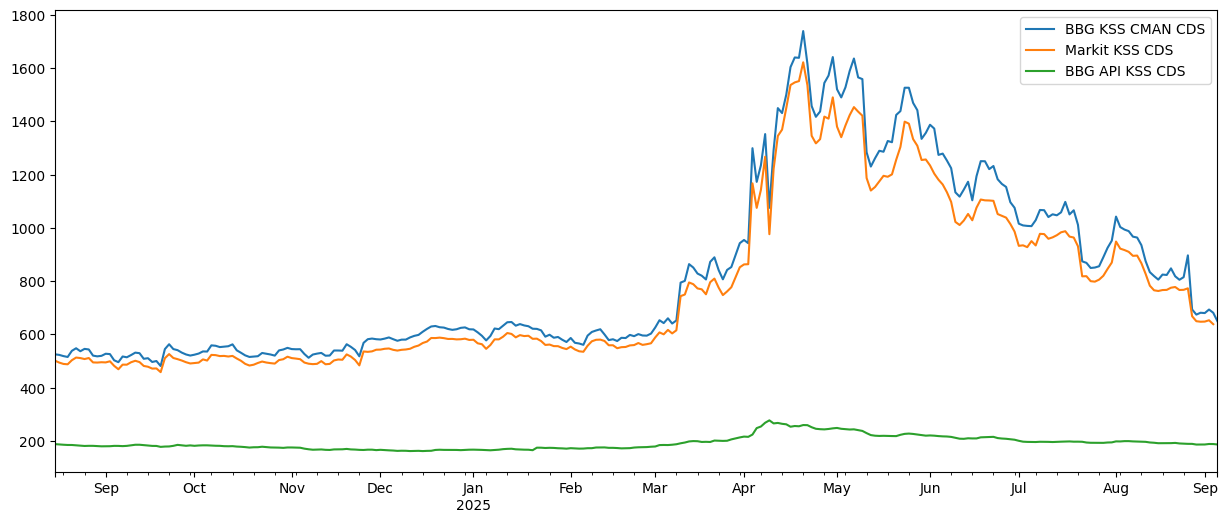

In [44]:
m1=m[["close_date","spread"]].copy()
m1["close_date"] = pd.to_datetime(m1["close_date"])
m1=m1.set_index("close_date")
m1.columns=["Markit KSS CDS"]
m2=pd.concat([df,m1],axis=1)
ax=m2.plot(figsize=(15,6))
cds1.plot(secondary_y=False,ax=ax)

In [43]:
# cds = blp.bdh(tickers="KSS CDS USD SR 5Y D14 Corp",flds="PX_LAST", start_date="2024-08-15")
cds1 = cds.copy()
cds1.columns = ["BBG API KSS CDS"]
cds1.index = pd.to_datetime(cds1.index)
cds1

,BBG API KSS CDS
2024-08-15,187.579
2024-08-16,186.318
2024-08-19,185.235
2024-08-20,184.356
2024-08-21,184.292
...,...
2025-08-29,186.051
2025-09-01,186.159
2025-09-02,188.062
2025-09-03,187.867


In [45]:
cds = blp.bdh(tickers="KSS CDS USD SR 5Y D14 Corp",flds="PX_LAST", start_date="2024-08-15")
cds

,KSS CDS USD SR 5Y D14 Corp
,PX_LAST
2024-08-15,187.579
2024-08-16,186.318
2024-08-19,185.235
2024-08-20,184.356
2024-08-21,184.292
...,...
2025-08-29,186.051
2025-09-01,186.159
2025-09-02,188.062


In [46]:
m2

,BBG KSS CMAN CDS,Markit KSS CDS
2024-08-15,524.995,501.1284
2024-08-16,522.835,493.9562
2024-08-19,518.295,488.8322
2024-08-20,515.000,487.4597
2024-08-21,538.130,502.8330
...,...,...
2025-08-29,681.155,647.3895
2025-09-01,679.975,647.9250
2025-09-02,693.190,652.8720
2025-09-03,681.090,638.1321
